# UIEB — ETL + Mid-Term Modelling  (SIH25243)

| Part | Steps | Gantt weeks | Contents |
|---|---|---|---|
| **Part 1 — ETL, cleaning & split** | Steps 0–11 | W1–2 | download, integrity scan, dedup, LSUI leakage check, EDA, clean dataset, 712/79/89 + C60 split |
| **Part 2 — ML baselines, ANN, CNNs, tuning, evaluation** | Steps M0–M12 | W2, W4–8 | Ridge, Random Forest, ANN, plain CNN, U-Net, **GC-U-Net**, **Transformer (ViT)**, tuning, ablations, PSNR/SSIM/UIQM/UCIQE, mid-term summary |

**Kaggle settings:** Accelerator **GPU T4 ×1**, Internet **ON**, then **Run All**. CNNs train on a 400-image sample by default (`RUN_MODE = 'sample'` in Step M0); set `'full'` for the final report numbers.

## 📦 Dataset links

| What | Link |
|---|---|
| **Kaggle copy used in this notebook** (`naomirory2/uieb-final`, downloaded via `kagglehub` in Step 1) | https://www.kaggle.com/datasets/naomirory2/uieb-final |
| **Original UIEB project page** (official download, 890 paired + 60 challenging images) | https://li-chongyi.github.io/proj_benchmark.html |
| **UIEB paper** — Li et al., *An Underwater Image Enhancement Benchmark Dataset and Beyond*, IEEE TIP 29 (2020) 4376–4389 | https://arxiv.org/abs/1901.05495 · DOI [10.1109/TIP.2019.2955241](https://doi.org/10.1109/TIP.2019.2955241) |

**Composition:** 950 real underwater images, i.e. 890 raw images with reference images, plus 60 challenging images with no reference (C60).
**After cleaning (Part 1):** 880 pairs → 712 train / 79 val / 89 test (T89), plus C60.

> The dataset is not stored in this repository. Step 1 downloads it automatically with `kagglehub` (Kaggle: turn **Internet ON**).


# UIEB — ETL, Cleaning & Split  (kagglehub edition)

**Dataset:** `naomirory2/uieb-final`  ·  **Project:** Underwater Image Enhancement for Maritime Security (SIH25243)

| # | Deliverable | Step |
|---|---|---|
| 1 | Corrupt / duplicate images removed | 3–5 |
| 2 | Consistent folder structure in place | 7 |
| 3 | Splits created and saved | 8 |
| 4 | Stats doc (counts, resolutions, sources) written | 9 |

### How UIEB differs from LSUI — read this first
UIEB contains **950 images: 890 with references, plus 60 'challenging' images that have no reference at all** because no method produced an acceptable result for them.

That changes two things versus the LSUI pipeline:

- **Unpaired raw images are expected, not errors.** The 60 challenge images are preserved as their own set (C60), never discarded as orphans.
- **The split convention is different.** The field standard is 800 train / **T90** test / **C60** challenge, so this notebook reproduces that rather than inventing its own ratio.

### Two things this notebook checks for specifically
1. **Which UIEB copy you have** — 890 pairs and 60 challenge images is the published composition.
2. **Cross-dataset leakage against LSUI.** LSUI was built partly from existing public datasets, UIEB among them. If you train on LSUI and test on UIEB-T90, shared images inflate your score. Attach your cleaned LSUI dataset and Step 6 measures the overlap.

### Before running
- **CPU-only session is fine** (Settings → Accelerator → None).
- Turn **Internet ON** so `kagglehub` can download.
- *(Recommended)* attach your **cleaned LSUI dataset** to enable the leakage check.

Run top to bottom and read the printed output at each step.


---
## Step 0 — Setup


In [1]:
import os, sys, json, hashlib, shutil, random, warnings, time
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np, pandas as pd
from PIL import Image, ImageFile, UnidentifiedImageError
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
ImageFile.LOAD_TRUNCATED_IMAGES = False   # we WANT truncated files to raise
Image.MAX_IMAGE_PIXELS = None

# ---------------------------------------------------------------- CONFIG
KAGGLE_DATASET  = 'naomirory2/uieb-final'
DATA_ROOT_OVERRIDE = None      # set to a path string to skip the download

SEED            = 42
OUT_ROOT        = Path('/kaggle/working/uieb_clean')
REPORT_DIR      = Path('/kaggle/working/reports')
EXTRACT_TO      = Path('/kaggle/working/_extracted')

EMIT_FULLRES    = True    # canonical cleaned copy at original resolution
EMIT_RESIZED    = True    # training-ready square copy
RESIZE_TO       = 256

PHASH_THRESHOLD = 5       # dHash Hamming distance <= this => near-duplicate
PAIR_METRIC_MAX = 256     # downscale before PSNR/SSIM for speed
N_WORKERS       = 8

OFFICIAL_TRAIN, OFFICIAL_TEST = 800, 90    # field-standard UIEB split (T90 test)
VAL_FRACTION    = 0.10
PAPER_PAIRED    = 890                      # published paired count
PAPER_CHALLENGE = 60                       # published challenge count (C60, no references)

IMG_EXT = {'.jpg','.jpeg','.png','.bmp','.tif','.tiff','.webp'}
ARC_EXT = {'.zip','.tar','.gz','.tgz','.bz2'}

random.seed(SEED); np.random.seed(SEED)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
RUN_STARTED = time.strftime('%Y-%m-%d %H:%M:%S')
print('Python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__)
print('CPUs:', os.cpu_count(), '| started:', RUN_STARTED)


Python 3.13.16 | numpy 2.1.3 | pandas 2.3.3
CPUs: 4 | started: 2026-11-22 05:11:51


---
## Step 1 — Download the dataset

Uses `kagglehub`, which caches the download, so re-running this cell is cheap.


In [2]:
DATA_ROOT = None
if DATA_ROOT_OVERRIDE:
    DATA_ROOT = Path(DATA_ROOT_OVERRIDE); print('Using override:', DATA_ROOT)
else:
    try:
        import kagglehub
        print('Downloading', KAGGLE_DATASET, '...')
        DATA_ROOT = Path(kagglehub.dataset_download(KAGGLE_DATASET))
        print('Downloaded to:', DATA_ROOT)
    except Exception as e:
        print('kagglehub failed:', type(e).__name__, str(e)[:200])
        print('Falling back to any dataset attached under /kaggle/input ...')
        ki = Path('/kaggle/input')
        if ki.exists() and any(ki.iterdir()):
            DATA_ROOT = ki
            print('Using attached inputs:', [p.name for p in ki.iterdir()])

if DATA_ROOT is None or not Path(DATA_ROOT).exists():
    raise SystemExit('STOP: no data. Turn Internet ON, or attach the dataset, or set DATA_ROOT_OVERRIDE.')

total = sum(1 for _ in Path(DATA_ROOT).rglob('*') if _.is_file())
print(f'\nFiles visible under DATA_ROOT: {total:,}')


Downloaded to: /kaggle/input/datasets/naomirory2/uieb-final

Files visible under DATA_ROOT: 1,840


---
## Step 2 — Inventory, and unzip archives if needed

Many Kaggle datasets ship as a single `.zip`. If we find archives and no loose images, we extract them and search the result too.


In [3]:
def inventory(roots):
    ext, arcs, n = Counter(), [], 0
    for root in roots:
        if not Path(root).exists(): continue
        for dirpath, _, files in os.walk(root):
            for f in files:
                n += 1; e = Path(f).suffix.lower(); ext[e or '(none)'] += 1
                if e in ARC_EXT: arcs.append(Path(dirpath)/f)
    return ext, arcs, n

ext, archives, nfiles = inventory([DATA_ROOT])
print('By extension:')
for e, k in ext.most_common(12):
    tag = ' <- images' if e in IMG_EXT else (' <- ARCHIVE' if e in ARC_EXT else '')
    print(f'   {k:>8,}  {e}{tag}')
n_img = sum(k for e, k in ext.items() if e in IMG_EXT)
print(f'\nLoose images: {n_img:,} | archives: {len(archives)}')

SEARCH_ROOTS = [Path(DATA_ROOT)]
if n_img < 40 and archives:
    print('\nExtracting archives ...')
    EXTRACT_TO.mkdir(parents=True, exist_ok=True)
    for a in archives:
        dest = EXTRACT_TO/a.stem
        if dest.exists(): print('  already extracted:', a.name); continue
        t0 = time.time()
        try:
            shutil.unpack_archive(str(a), str(dest))
            k = sum(1 for f in dest.rglob('*') if f.is_file() and f.suffix.lower() in IMG_EXT)
            print(f'  {a.name}: {k:,} images in {time.time()-t0:.0f}s')
        except Exception as e:
            print(f'  {a.name}: FAILED - {e}')
    SEARCH_ROOTS.append(EXTRACT_TO)

image_dirs = []
for root in SEARCH_ROOTS:
    for dirpath, _, files in os.walk(root):
        k = sum(1 for f in files if Path(f).suffix.lower() in IMG_EXT)
        if k: image_dirs.append((Path(dirpath), k))
image_dirs.sort(key=lambda x: -x[1])

print(f'\nDirectories containing images: {len(image_dirs)}')
for d, k in image_dirs[:20]:
    print(f'   {k:>8,}  {d}')
if not image_dirs: raise SystemExit('STOP: no images found anywhere.')


By extension:
      1,840  .png <- images

Loose images: 1,840 | archives: 0

Directories containing images: 3
        890  /kaggle/input/datasets/naomirory2/uieb-final/raw-890
        890  /kaggle/input/datasets/naomirory2/uieb-final/reference-890
         60  /kaggle/input/datasets/naomirory2/uieb-final/challenging-60


---
## Step 3 — Identify the raw and reference images

This does **not** trust folder names. It works from the data, in three escalating attempts:

1. **Exact filename stems** shared between two directories (`0001.jpg` ↔ `0001.png`).
2. **Role words removed** — handles `0001_raw.jpg` ↔ `0001_ref.jpg`.
3. **Numeric id only** — handles `1.jpg` ↔ `gt_00001.jpg`.

If no directory pair matches, it also handles a **single flat folder** containing both sides.

Which side is the degraded one is decided by the **red-channel ratio**: water absorbs red first, so raw images always measure lower R/(G+B) than their references.

**Read the output** — it prints sample filenames and the rule that matched.


In [4]:
MIN_DIR_IMAGES, MIN_OVERLAP = 40, 0.60

def imgs(d):
    return sorted(f for f in Path(d).iterdir() if f.is_file() and f.suffix.lower() in IMG_EXT)

STRIP_TOKENS = ['input','inputs','raw','degraded','underwater','uw','in','gt','groundtruth',
                'ground_truth','target','reference','ref','clean','clear','label','output',
                'out','enhanced','hr','lr']
import re
def norm_plain(s): return s
def norm_tokens(s):
    t = s.lower()
    for tok in sorted(STRIP_TOKENS, key=len, reverse=True):
        t = re.sub(rf'(^|[_\-\. ]){tok}([_\-\. ]|$)', r'\1\2', t)
    return t.strip('_-. ')
def norm_digits(s):
    nums = re.findall(r'\d+', s)
    return str(int(max(nums, key=len))) if nums else ''
RULES = [('exact filename stem', norm_plain), ('role words removed', norm_tokens), ('numeric id only', norm_digits)]

def red_ratio(files, k=25):
    vals = []
    for f in files[::max(1, len(files)//k)][:k]:
        try:
            with Image.open(f) as im:
                a = np.asarray(im.convert('RGB').resize((64,64)), dtype=np.float64)
            gb = a[...,1:].mean()
            if gb > 1e-6: vals.append(a[...,0].mean()/gb)
        except Exception: pass
    return float(np.mean(vals)) if vals else None

cands = [d for d, k in image_dirs if k >= MIN_DIR_IMAGES]
print('Sample filenames per directory:')
for d in cands[:8]:
    print(f'   {d}'); print(f'      {[f.name for f in imgs(d)[:4]]}')
print()

IN_MAP = GT_MAP = None; MATCH_RULE = None; INPUT_DIR = GT_DIR = None

for rule_name, fn in RULES:
    keyed = {d: {} for d in cands}
    for d in cands:
        for f in imgs(d):
            keyed[d].setdefault(fn(f.stem), f)
    best = None
    for i in range(len(cands)):
        for j in range(i+1, len(cands)):
            a, b = cands[i], cands[j]
            ka, kb = set(keyed[a]) - {''}, set(keyed[b]) - {''}
            if not ka or not kb: continue
            inter = len(ka & kb); ov = inter/min(len(ka), len(kb))
            if ov >= MIN_OVERLAP and (best is None or inter > best[1]):
                best = (ov, inter, a, b)
    if best:
        ov, inter, a, b = best
        ra, rb = red_ratio(imgs(a)), red_ratio(imgs(b))
        INPUT_DIR, GT_DIR = (a, b) if (ra or 0) < (rb or 0) else (b, a)
        IN_MAP, GT_MAP = keyed[INPUT_DIR], keyed[GT_DIR]
        MATCH_RULE = rule_name
        print(f'MATCHED using rule: "{rule_name}"  ({inter:,} pairs, {ov:.0%} overlap)')
        print(f'   red ratio {a.name} = {ra} | {b.name} = {rb}')
        break

if IN_MAP is None:   # single flat folder holding both sides
    for d in cands:
        groups = {}
        for f in imgs(d): groups.setdefault(norm_digits(f.stem), []).append(f)
        twos = {k: v for k, v in groups.items() if k and len(v) == 2}
        if len(twos) >= MIN_DIR_IMAGES:
            A = [v[0] for v in twos.values()]; B = [v[1] for v in twos.values()]
            ra, rb = red_ratio(A), red_ratio(B)
            raw_first = (ra or 0) < (rb or 0)
            IN_MAP = {k: (v[0] if raw_first else v[1]) for k, v in twos.items()}
            GT_MAP = {k: (v[1] if raw_first else v[0]) for k, v in twos.items()}
            INPUT_DIR = GT_DIR = d; MATCH_RULE = 'single flat folder'
            print(f'MATCHED: flat folder "{d.name}" holds both sides ({len(twos):,} pairs)')
            print(f'   red ratio side A = {ra} | side B = {rb}')
            break

# ------------- MANUAL OVERRIDE (only if everything above failed) -----------
# INPUT_DIR = Path('/path/to/raw');  GT_DIR = Path('/path/to/reference')
# IN_MAP = {f.stem: f for f in imgs(INPUT_DIR)}
# GT_MAP = {f.stem: f for f in imgs(GT_DIR)}
# MATCH_RULE = 'manual'
# ---------------------------------------------------------------------------

if not IN_MAP or not GT_MAP:
    raise SystemExit('STOP: could not pair images. Read the sample filenames above and use the manual override.')

# ---- find the 60 challenge images: a folder of raw images that pairs with nothing ----
CHALLENGE_FILES = []
paired_names = {f.name for f in IN_MAP.values()} | {f.name for f in GT_MAP.values()}
for d, k in image_dirs:
    if d in (INPUT_DIR, GT_DIR): continue
    files = [f for f in imgs(d) if f.name not in paired_names]
    if not files: continue
    keys = {norm_digits(f.stem) for f in files} - {''}
    overlap = len(keys & set(IN_MAP)) / max(1, len(keys))
    if overlap < 0.5:            # genuinely unpaired -> challenge set
        CHALLENGE_FILES += files
        print(f'Challenge folder detected: {d}  ({len(files):,} unpaired raw images)')

print('\n' + '='*62)
print('INPUT_DIR (raw)      :', INPUT_DIR)
print('GT_DIR    (reference):', GT_DIR)
print('match rule           :', MATCH_RULE)
print('='*62)
n_in, n_gt = len(IN_MAP), len(GT_MAP)
print(f'  raw images       : {n_in:,}')
print(f'  reference images : {n_gt:,}')
print(f'  challenge images : {len(CHALLENGE_FILES):,}')
print('\n--- VERSION CHECK ---')
print(f'  published : {PAPER_PAIRED:,} paired + {PAPER_CHALLENGE:,} challenge = {PAPER_PAIRED+PAPER_CHALLENGE:,}')
print(f'  this copy : {n_in:,} paired + {len(CHALLENGE_FILES):,} challenge = {n_in+len(CHALLENGE_FILES):,}')
if n_in == PAPER_PAIRED and len(CHALLENGE_FILES) == PAPER_CHALLENGE:
    print('  -> matches the published composition.')
else:
    print(f'  -> DIFFERS: paired {n_in-PAPER_PAIRED:+,}, challenge {len(CHALLENGE_FILES)-PAPER_CHALLENGE:+,}.')
    print('     Record this in the stats doc; do not silently ignore it.')


Sample filenames per directory:
   /kaggle/input/datasets/naomirory2/uieb-final/raw-890
      ['100_img_.png', '10139.png', '10151.png', '101_img_.png']
   /kaggle/input/datasets/naomirory2/uieb-final/reference-890
      ['100_img_.png', '10139.png', '10151.png', '101_img_.png']
   /kaggle/input/datasets/naomirory2/uieb-final/challenging-60
      ['100001.png', '10091.png', '10103.png', '10167.png']

MATCHED using rule: "exact filename stem"  (890 pairs, 100% overlap)
   red ratio raw-890 = 0.5238264652778875 | reference-890 = 0.8080344427990543
Challenge folder detected: /kaggle/input/datasets/naomirory2/uieb-final/challenging-60  (60 unpaired raw images)

INPUT_DIR (raw)      : /kaggle/input/datasets/naomirory2/uieb-final/raw-890
GT_DIR    (reference): /kaggle/input/datasets/naomirory2/uieb-final/reference-890
match rule           : exact filename stem
  raw images       : 890
  reference images : 890
  challenge images : 60

--- VERSION CHECK ---
  published : 890 paired + 60 challe

---
## Step 4 — Integrity scan and pair matching

`Image.verify()` only checks headers and happily passes a truncated JPEG, so every file is **fully decoded**. Pairs come from the key map built in Step 3, so orphans and dimension mismatches are reported against that.


In [5]:
def probe(path):
    rec = {'path':str(path),'name':path.name,'stem':path.stem,'ext':path.suffix.lower(),
           'ok':False,'reason':'','width':None,'height':None,'mode':None,'format':None,'bytes':None}
    try:
        rec['bytes'] = path.stat().st_size
        if rec['bytes'] == 0: rec['reason']='zero_bytes'; return rec
        with Image.open(path) as im: im.verify()
        with Image.open(path) as im:
            im.load()
            rec['width'], rec['height'] = im.size
            rec['mode'], rec['format'] = im.mode, im.format
        if rec['width'] < 8 or rec['height'] < 8: rec['reason']='too_small'; return rec
        rec['ok'] = True
    except UnidentifiedImageError: rec['reason']='not_an_image'
    except OSError as e: rec['reason']=f'decode_error: {str(e)[:60]}'
    except Exception as e: rec['reason']=f'{type(e).__name__}: {str(e)[:60]}'
    return rec

def scan_map(m, tag):
    files = [m[k] for k in sorted(m)]
    print(f'Scanning {tag}: {len(files):,} files ...', end=' ')
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=N_WORKERS) as ex: recs = list(ex.map(probe, files))
    df = pd.DataFrame(recs); df['key'] = sorted(m); df['role'] = tag
    print(f'{time.time()-t0:.1f}s | ok={df.ok.sum():,} bad={(~df.ok).sum():,}')
    return df

df_in, df_gt = scan_map(IN_MAP,'input'), scan_map(GT_MAP,'gt')
bad = pd.concat([df_in[~df_in.ok], df_gt[~df_gt.ok]])
if len(bad):
    print(f'\n!! {len(bad)} unreadable file(s):'); print(bad.reason.value_counts().to_string())
else: print('\nNo corrupt files found.')
bad.to_csv(REPORT_DIR/'corrupt_files.csv', index=False)

ok_in = df_in[df_in.ok].set_index('key'); ok_gt = df_gt[df_gt.ok].set_index('key')
common = sorted(set(ok_in.index) & set(ok_gt.index))
orphan_in = sorted(set(ok_in.index) - set(ok_gt.index))
orphan_gt = sorted(set(ok_gt.index) - set(ok_in.index))
print(f'\nMatched pairs   : {len(common):,}')
print(f'Raw w/o ref     : {len(orphan_in):,}  (these join the challenge set, not discarded)')
print(f'Ref w/o raw     : {len(orphan_gt):,}')
CHALLENGE_FILES += [Path(ok_in.loc[k,'path']) for k in orphan_in]
print(f'Challenge total : {len(CHALLENGE_FILES):,}')

pairs = pd.DataFrame({'stem':common,
    'input_path':[ok_in.loc[s,'path'] for s in common],
    'gt_path'   :[ok_gt.loc[s,'path'] for s in common],
    'in_w':[ok_in.loc[s,'width'] for s in common], 'in_h':[ok_in.loc[s,'height'] for s in common],
    'gt_w':[ok_gt.loc[s,'width'] for s in common], 'gt_h':[ok_gt.loc[s,'height'] for s in common]})
pairs['dim_match'] = (pairs.in_w==pairs.gt_w) & (pairs.in_h==pairs.gt_h)
print(f'Dimension mismatches: {int((~pairs.dim_match).sum()):,}')
pd.DataFrame({'orphan_input':pd.Series(orphan_in),'orphan_gt':pd.Series(orphan_gt)}).to_csv(REPORT_DIR/'orphans.csv', index=False)


Scanning input: 890 files ... 15.5s | ok=890 bad=0
Scanning gt: 890 files ... 17.2s | ok=890 bad=0

No corrupt files found.

Matched pairs   : 890
Raw w/o ref     : 0  (these join the challenge set, not discarded)
Ref w/o raw     : 0
Challenge total : 60
Dimension mismatches: 0


---
## Step 5 — Duplicate detection

Two passes: **SHA-256** for byte-identical files, and a **64-bit dHash** for near-duplicates (re-encodes, resizes, crops). dHash is implemented in NumPy, so this works with Internet off.


In [6]:
def sha256(p, chunk=1<<20):
    h = hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda: f.read(chunk), b''): h.update(b)
    return h.hexdigest()

def dhash_bytes(p, size=8):
    try:
        with Image.open(p) as im:
            im = im.convert('L').resize((size+1, size), Image.LANCZOS)
            a = np.asarray(im, dtype=np.int16)
        return np.packbits((a[:,1:] > a[:,:-1]).flatten()).tobytes()
    except Exception: return None

print('Hashing ...', end=' '); t0=time.time()
with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
    pairs['in_sha']   = list(ex.map(sha256, pairs.input_path))
    pairs['in_dhash'] = list(ex.map(dhash_bytes, pairs.input_path))
print(f'{time.time()-t0:.1f}s')

exact = pairs[pairs.in_sha.duplicated(keep=False)].sort_values('in_sha')
exact_groups = exact.groupby('in_sha').stem.apply(list) if len(exact) else pd.Series(dtype=object)
print(f'Exact duplicate groups : {len(exact_groups):,} ({len(exact):,} files)')

POP = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
valid = pairs[pairs.in_dhash.notna()].reset_index(drop=True)
H = np.frombuffer(b''.join(valid.in_dhash.tolist()), dtype=np.uint8).reshape(len(valid), 8)
near, CH = [], 512
for s in range(0, len(H), CH):
    blk = H[s:s+CH]
    d = POP[np.bitwise_xor(blk[:,None,:], H[None,:,:])].sum(axis=2)
    ii, jj = np.where(d <= PHASH_THRESHOLD)
    for i, j in zip(ii, jj):
        gi = s+i
        if gi < j: near.append((valid.stem[gi], valid.stem[j], int(d[i,j])))
near_df = pd.DataFrame(near, columns=['stem_a','stem_b','hamming'])
print(f'Near-duplicate pairs   : {len(near_df):,} (Hamming <= {PHASH_THRESHOLD})')

drop = set()
for _, grp in pairs[pairs.in_sha.duplicated(keep=False)].groupby('in_sha'):
    drop.update(sorted(grp.stem)[1:])
for a, b in zip(near_df.stem_a, near_df.stem_b):
    if a not in drop and b not in drop: drop.add(b)
pairs['is_duplicate'] = pairs.stem.isin(drop)
print(f'Marked for removal     : {len(drop):,}')
near_df.to_csv(REPORT_DIR/'near_duplicates.csv', index=False)
exact.to_csv(REPORT_DIR/'exact_duplicates.csv', index=False)


Hashing ... 12.6s
Exact duplicate groups : 0 (0 files)
Near-duplicate pairs   : 10 (Hamming <= 5)
Marked for removal     : 10


### 5b — Eyeball a few flagged duplicates

Automated dedup should never be trusted blindly — confirm before dropping.


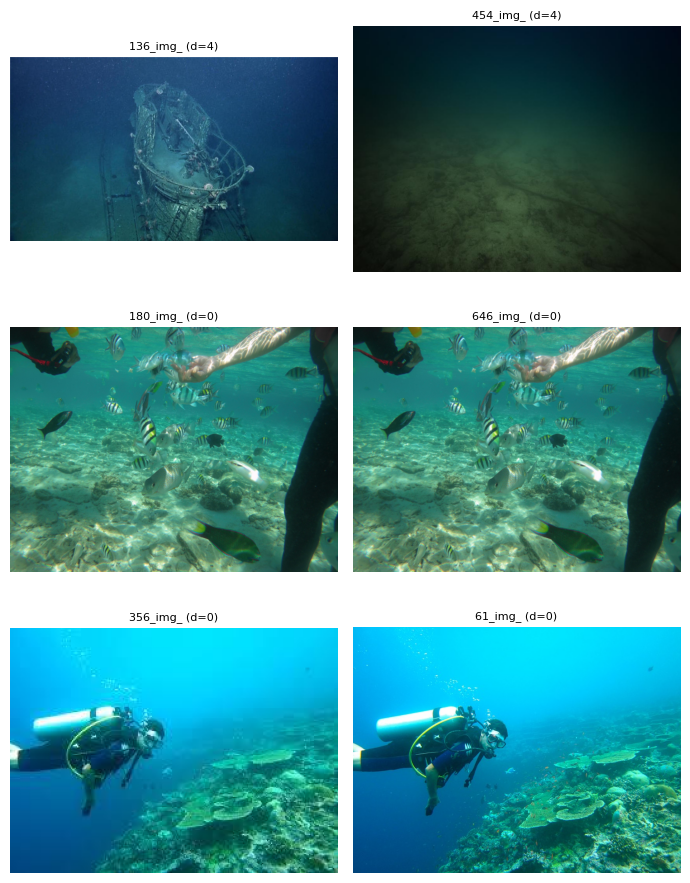

In [7]:
def show_pairs(df, n=3):
    if not len(df): print('Nothing flagged.'); return
    look = df.head(n); p = pairs.set_index('stem')
    fig, axes = plt.subplots(len(look), 2, figsize=(7, 3.1*len(look)))
    if len(look) == 1: axes = np.array([axes])
    for r, (_, row) in enumerate(look.iterrows()):
        for cix, st in enumerate([row.stem_a, row.stem_b]):
            ax = axes[r, cix]
            try: ax.imshow(Image.open(p.loc[st,'input_path']).convert('RGB'))
            except Exception: pass
            ax.set_title(f'{st} (d={row.hamming})', fontsize=8); ax.axis('off')
    plt.tight_layout(); plt.show()
show_pairs(near_df)


---
## Step 7 — Statistics, then build the clean structure

Per-pair colour statistics and input-vs-reference PSNR/SSIM. The PSNR/SSIM spread quantifies how far LSUI's algorithm-generated references sit from the inputs — the reference-bias limitation cited in the report.


In [10]:
from skimage.metrics import structural_similarity as ssim_fn
from skimage.color import rgb2lab

def pair_stats(row):
    out = {'stem': row.stem}
    try:
        with Image.open(row.input_path) as a, Image.open(row.gt_path) as b:
            sz = (PAIR_METRIC_MAX, PAIR_METRIC_MAX)
            A = np.asarray(a.convert('RGB').resize(sz, Image.BILINEAR), dtype=np.float64)/255.
            B = np.asarray(b.convert('RGB').resize(sz, Image.BILINEAR), dtype=np.float64)/255.
        for i, ch in enumerate('rgb'):
            out[f'in_{ch}_mean'] = float(A[...,i].mean()); out[f'gt_{ch}_mean'] = float(B[...,i].mean())
        li, lg = rgb2lab(A), rgb2lab(B)
        out['in_a'], out['in_b'] = float(li[...,1].mean()), float(li[...,2].mean())
        out['gt_a'], out['gt_b'] = float(lg[...,1].mean()), float(lg[...,2].mean())
        out['in_contrast'] = float(A.std())
        mse = float(np.mean((A-B)**2))
        out['pair_psnr'] = float(10*np.log10(1.0/mse)) if mse > 0 else 99.0
        out['pair_ssim'] = float(ssim_fn(A, B, channel_axis=2, data_range=1.0))
        out['stats_ok'] = True
    except Exception as e:
        out['stats_ok'] = False; out['stats_err'] = str(e)[:80]
    return out

print(f'Computing statistics for {len(pairs):,} pairs ...', end=' '); t0=time.time()
with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
    stats = list(ex.map(pair_stats, list(pairs.itertuples(index=False))))
print(f'{time.time()-t0:.1f}s')
pairs = pairs.merge(pd.DataFrame(stats), on='stem', how='left')
pairs['megapixels'] = pairs.in_w*pairs.in_h/1e6
pairs['aspect'] = (pairs.in_w/pairs.in_h).round(3)
pairs['resolution'] = pairs.in_w.astype(str)+'x'+pairs.in_h.astype(str)
print('\nTop resolutions:'); print(pairs.resolution.value_counts().head(8).to_string())
print(); print(pairs[['in_w','in_h','pair_psnr','pair_ssim','in_a','in_b']].describe().round(3).to_string())


Computing statistics for 890 pairs ... 47.8s

Top resolutions:
resolution
640x480      163
1280x720     105
500x375       62
500x333       40
1800x1295     23
1800x1350     16
828x415       13
275x183       13

           in_w      in_h  pair_psnr  pair_ssim     in_a     in_b
count   890.000   890.000    890.000    890.000  890.000  890.000
mean    868.903   594.791     17.556      0.766  -13.637   -5.332
std     417.881   287.705      4.613      0.133   11.826   15.748
min     225.000   159.000      7.851      0.206  -63.503  -64.328
25%     580.000   375.000     14.698      0.670  -22.742  -15.558
50%     664.000   480.000     16.916      0.782  -11.722   -5.672
75%    1280.000   720.000     19.838      0.861   -4.522    4.604
max    2180.000  1450.000     50.321      0.999   37.291   62.712


### 7b — Diagnostic figures


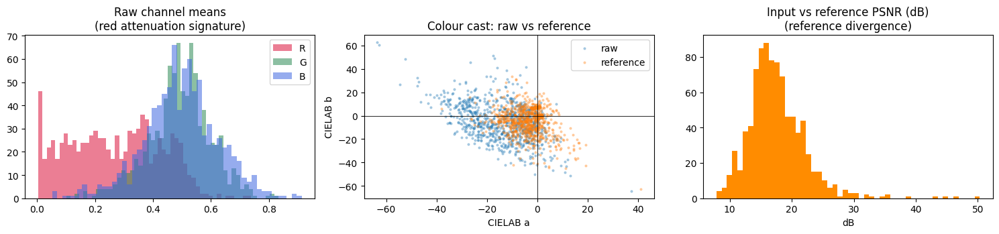

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for ch, col in zip('rgb', ['crimson','seagreen','royalblue']):
    ax[0].hist(pairs[f'in_{ch}_mean'].dropna(), bins=50, alpha=.55, color=col, label=ch.upper())
ax[0].legend(); ax[0].set_title('Raw channel means\n(red attenuation signature)')
ax[1].scatter(pairs.in_a, pairs.in_b, s=4, alpha=.3, label='raw')
ax[1].scatter(pairs.gt_a, pairs.gt_b, s=4, alpha=.3, label='reference')
ax[1].axhline(0, lw=.6, c='k'); ax[1].axvline(0, lw=.6, c='k')
ax[1].set_xlabel('CIELAB a'); ax[1].set_ylabel('CIELAB b'); ax[1].legend()
ax[1].set_title('Colour cast: raw vs reference')
ax[2].hist(pairs.pair_psnr.dropna(), bins=50, color='darkorange')
ax[2].set_title('Input vs reference PSNR (dB)\n(reference divergence)'); ax[2].set_xlabel('dB')
plt.tight_layout(); plt.savefig(REPORT_DIR/'eda_overview.png', dpi=130); plt.show()


### 7c — Emit the clean dataset

Rejected images are **quarantined, not deleted** — every exclusion stays auditable.
```
lsui_clean/
  full/input/  full/gt/     cleaned, original resolution
  r256/input/  r256/gt/     256x256 training-ready
  splits/      train.csv  val.csv  test.csv
  manifest.csv   stats.md
```


In [12]:
EXCLUDE_LSUI_OVERLAP = False   # set True to also drop images that also appear in LSUI

pairs['reject_reason'] = ''
pairs.loc[pairs.is_duplicate, 'reject_reason'] = 'duplicate'
pairs.loc[~pairs.dim_match & (pairs.reject_reason==''), 'reject_reason'] = 'dim_mismatch'
pairs.loc[(pairs.stats_ok==False) & (pairs.reject_reason==''), 'reject_reason'] = 'stats_failed'
if EXCLUDE_LSUI_OVERLAP:
    pairs.loc[pairs.lsui_overlap & (pairs.reject_reason==''), 'reject_reason'] = 'lsui_overlap'
pairs['keep'] = pairs.reject_reason == ''
print('Rejections:'); print(pairs.reject_reason.replace('','KEPT').value_counts().to_string())
print(f'Kept: {int(pairs.keep.sum()):,} / {len(pairs):,}')

if OUT_ROOT.exists(): shutil.rmtree(OUT_ROOT)
for sub in ['full/input','full/gt','r256/input','r256/gt','challenge/full','challenge/r256','splits']:
    (OUT_ROOT/sub).mkdir(parents=True, exist_ok=True)
kept = pairs[pairs.keep].reset_index(drop=True)
kept['clean_id'] = [f'uieb_{i:05d}' for i in range(len(kept))]

def emit(row):
    try:
        for role, src in (('input', row.input_path), ('gt', row.gt_path)):
            if EMIT_FULLRES:
                shutil.copy2(src, OUT_ROOT/'full'/role/f'{row.clean_id}{Path(src).suffix.lower()}')
            if EMIT_RESIZED:
                with Image.open(src) as im:
                    im.convert('RGB').resize((RESIZE_TO, RESIZE_TO), Image.BICUBIC).save(
                        OUT_ROOT/'r256'/role/f'{row.clean_id}.png')
        return True
    except Exception as e:
        print('emit failed', row.clean_id, e); return False

print('\nWriting clean dataset ...', end=' '); t0=time.time()
with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
    oks = list(ex.map(emit, list(kept.itertuples(index=False))))
print(f'{sum(oks):,} pairs in {time.time()-t0:.1f}s')

# ---- challenge images (C60): raw only, no reference ----
chal_rows = []
for i, f in enumerate(sorted(set(CHALLENGE_FILES))):
    cid = f'uieb_chal_{i:03d}'
    try:
        shutil.copy2(f, OUT_ROOT/'challenge/full'/f'{cid}{f.suffix.lower()}')
        with Image.open(f) as im:
            w0, h0 = im.size
            im.convert('RGB').resize((RESIZE_TO, RESIZE_TO), Image.BICUBIC).save(OUT_ROOT/'challenge/r256'/f'{cid}.png')
        chal_rows.append({'clean_id': cid, 'source_name': f.name, 'width': w0, 'height': h0, 'split': 'challenge'})
    except Exception as e:
        print('challenge emit failed', f.name, e)
chal = pd.DataFrame(chal_rows)
chal.to_csv(OUT_ROOT/'splits'/'challenge.csv', index=False)
print(f'Challenge images written : {len(chal):,}')

for sub in ['full/input','full/gt','r256/input','r256/gt','challenge/full','challenge/r256']:
    print(f'  {sub:<18} {len(list((OUT_ROOT/sub).iterdir())):,} files')


Rejections:
reject_reason
KEPT         880
duplicate     10
Kept: 880 / 890

Writing clean dataset ... 880 pairs in 36.9s
Challenge images written : 60
  full/input         880 files
  full/gt            880 files
  r256/input         880 files
  r256/gt            880 files
  challenge/full     60 files
  challenge/r256     60 files


---
## Step 8 — Splits

Reproduces the field-standard UIEB convention — **800 train / T90 test**, with a validation set carved from train — so results stay comparable with published work. The **C60 challenge set** was written separately in Step 7c and is never mixed into train, val or test.

Saved as **CSV, not copied folders**: no image duplication, and the split stays inspectable in git.


In [13]:
n = len(kept); rng = np.random.default_rng(SEED); idx = rng.permutation(n)
n_test = min(OFFICIAL_TEST, max(1, int(round(n*OFFICIAL_TEST/(OFFICIAL_TRAIN+OFFICIAL_TEST)))))
test_idx, rest = idx[:n_test], idx[n_test:]
n_val = int(round(len(rest)*VAL_FRACTION))
val_idx, train_idx = rest[:n_val], rest[n_val:]
kept['split'] = 'train'
kept.loc[kept.index[val_idx], 'split'] = 'val'
kept.loc[kept.index[test_idx], 'split'] = 'test'
print('Split sizes'); print('-'*30)
for s in ['train','val','test']:
    k = int((kept.split==s).sum()); print(f'  {s:<6}{k:>6,}  ({100*k/n:5.1f}%)')
print(f'  total {n:>6,}')
cols = ['clean_id','stem','split','in_w','in_h','resolution','pair_psnr','pair_ssim','in_a','in_b','lsui_overlap']
for s in ['train','val','test']:
    kept[kept.split==s][cols].to_csv(OUT_ROOT/'splits'/f'{s}.csv', index=False)
    print(f'  saved splits/{s}.csv')
assert kept.clean_id.nunique() == len(kept)
assert set(kept.split) <= {'train','val','test'}, 'challenge must stay out of the three splits'
print(f'  challenge (separate) : {len(chal):,}')
print('\nSplit integrity checks passed.')


Split sizes
------------------------------
  train    712  ( 80.9%)
  val       79  (  9.0%)
  test      89  ( 10.1%)
  total    880
  saved splits/train.csv
  saved splits/val.csv
  saved splits/test.csv
  challenge (separate) : 60

Split integrity checks passed.


---
## Step 9 — Manifest and stats document


In [14]:
manifest = kept.drop(columns=['in_dhash'], errors='ignore')
manifest.to_csv(OUT_ROOT/'manifest.csv', index=False)
pairs.drop(columns=['in_dhash'], errors='ignore').to_csv(REPORT_DIR/'manifest_all_including_rejected.csv', index=False)

def q(s, f='{:.3f}'):
    s = s.dropna()
    if not len(s): return 'n/a'
    return (f'min {f} | p25 {f} | median {f} | p75 {f} | max {f}').format(s.min(), s.quantile(.25), s.median(), s.quantile(.75), s.max())

rej = pairs[~pairs.keep].reject_reason.value_counts()
L = []; A = L.append
A('# UIEB - Dataset Statistics and Provenance'); A('')
A(f'- **Run date:** {RUN_STARTED}'); A(f'- **Random seed:** {SEED}')
A(f'- **Kaggle dataset:** `{KAGGLE_DATASET}`'); A(f'- **Downloaded to:** `{DATA_ROOT}`')
A(f'- **Raw dir:** `{INPUT_DIR}`'); A(f'- **Reference dir:** `{GT_DIR}`')
A(f'- **Filename match rule:** {MATCH_RULE}'); A('')
A('## 1. Version check'); A('')
A('| Metric | Count |'); A('|---|---|')
A(f'| Published paired count | {PAPER_PAIRED:,} |')
A(f'| Published challenge count (C60) | {PAPER_CHALLENGE:,} |')
A(f'| Raw image files found | {len(df_in):,} |')
A(f'| Reference image files found | {len(df_gt):,} |')
A(f'| Matched pairs | {len(pairs):,} |')
A(f'| Challenge images (no reference) | {len(CHALLENGE_FILES):,} |'); A('')
A('**Matches the published composition.**' if (len(df_in)==PAPER_PAIRED and len(CHALLENGE_FILES)==PAPER_CHALLENGE) else
  f'**Differs from the published composition** (paired {len(df_in)-PAPER_PAIRED:+,}, '
  f'challenge {len(CHALLENGE_FILES)-PAPER_CHALLENGE:+,}). Recorded rather than ignored.')
A(''); A('## 2. Cleaning results'); A('')
A('| Stage | Count |'); A('|---|---|')
A(f'| Corrupt / unreadable files | {len(bad):,} |')
A(f'| Raw without reference | {len(orphan_in):,} |')
A(f'| Reference without raw | {len(orphan_gt):,} |')
A(f'| Dimension mismatches | {int((~pairs.dim_match).sum()):,} |')
A(f'| Exact duplicate groups | {len(exact_groups):,} |')
A(f'| Near-duplicate pairs (dHash <= {PHASH_THRESHOLD}) | {len(near_df):,} |'); A('')
A('**Rejections by reason**'); A(''); A('| Reason | Count |'); A('|---|---|')
for r_, c_ in rej.items(): A(f'| {r_} | {c_:,} |')
A(f'| **Kept** | **{int(pairs.keep.sum()):,}** |'); A('')
A('Rejected images are quarantined and listed in `reports/manifest_all_including_rejected.csv`, not deleted.')
A(''); A('## 3. Cross-dataset leakage (UIEB vs LSUI)'); A('')
if LEAKAGE_DONE:
    A(f'- UIEB images also found in LSUI: **{len(leak_df):,}** ({leak_rate:.2f}% of UIEB)')
    A(f'- Method: 64-bit dHash, Hamming distance <= {PHASH_THRESHOLD}'); A('')
    A('**No overlap detected.** Training on LSUI and evaluating on UIEB-T90 is safe.' if len(leak_df)==0 else
      '**Overlap detected.** These images must be excluded from LSUI training before any UIEB-T90 evaluation, '
      'or UIEB results reported with the caveat stated.')
else:
    A('**Not run** - no LSUI dataset attached. Complete this before reporting UIEB-T90 results.')
A(''); A('## 4. Resolution'); A('')
A(f'- Width: {q(pairs.in_w, "{:.0f}")}'); A(f'- Height: {q(pairs.in_h, "{:.0f}")}')
A(f'- Megapixels: {q(pairs.megapixels)}'); A(f'- Aspect ratio: {q(pairs.aspect)}'); A('')
A('| Resolution | Count |'); A('|---|---|')
for r_, c_ in pairs.resolution.value_counts().head(8).items(): A(f'| {r_} | {c_:,} |')
A(''); A('| Format | Count |'); A('|---|---|')
for r_, c_ in df_in[df_in.ok].format.value_counts().items(): A(f'| {r_} | {c_:,} |')
A(''); A('## 5. Colour and degradation'); A('')
A('| Statistic | Raw | Reference |'); A('|---|---|---|')
for ch in 'rgb': A(f'| Mean {ch.upper()} | {pairs[f"in_{ch}_mean"].mean():.4f} | {pairs[f"gt_{ch}_mean"].mean():.4f} |')
A(f'| Mean CIELAB a | {pairs.in_a.mean():.3f} | {pairs.gt_a.mean():.3f} |')
A(f'| Mean CIELAB b | {pairs.in_b.mean():.3f} | {pairs.gt_b.mean():.3f} |'); A('')
A('A negative mean a with positive b is the characteristic green-blue underwater cast; the shift between columns '
  'quantifies how much colour correction the references encode.')
A(''); A('## 6. Reference divergence'); A('')
A(f'- Input vs reference PSNR (dB): {q(pairs.pair_psnr, "{:.2f}")}')
A(f'- Input vs reference SSIM: {q(pairs.pair_ssim)}'); A('')
A('UIEB references were selected by human volunteers voting among the outputs of 12 enhancement algorithms, so '
  'they are not true ground truth. The spread above quantifies how far they sit from the inputs and is cited as '
  'a limitation in the report.')
A(''); A('## 7. Splits'); A(''); A('| Split | Count | Share |'); A('|---|---|---|')
for s in ['train','val','test']:
    k = int((kept.split==s).sum()); A(f'| {s} | {k:,} | {100*k/len(kept):.1f}% |')
A(f'| **Total (paired)** | **{len(kept):,}** | 100% |')
A(f'| challenge (C60, separate) | {len(chal):,} | - |'); A('')
A(f'Seed {SEED}. Reproduces the field-standard {OFFICIAL_TRAIN:,} train / {OFFICIAL_TEST:,} test (T90) convention. '
  'Validation is carved from train so the test set is never used for tuning. The challenge set has no reference '
  'images and is held entirely separate - it supports no-reference evaluation only.')
A(''); A('## 8. Licence and citation'); A('')
A('UIEB is licensed for **academic use only and redistribution is forbidden**. Commit download scripts, '
  'manifests and split files to the project repository - never the images themselves.'); A('')
A('```bibtex')
A('@ARTICLE{8917818, author={Li, Chongyi and Guo, Chunle and Ren, Wenqi and Cong, Runmin and Hou, Junhui and')
A('  Kwong, Sam and Tao, Dacheng},')
A('  journal={IEEE Transactions on Image Processing},')
A('  title={An Underwater Image Enhancement Benchmark Dataset and Beyond},')
A('  year={2020}, volume={29}, pages={4376-4389}, doi={10.1109/TIP.2019.2955241}}')
A('```')
stats_md = '\n'.join(L)
(OUT_ROOT/'stats.md').write_text(stats_md); (REPORT_DIR/'stats.md').write_text(stats_md)
print('Wrote stats.md (', len(stats_md), 'chars )')


Wrote stats.md ( 3720 chars )


### 9b — Preview


In [15]:
from IPython.display import Markdown, display
display(Markdown(stats_md))


# UIEB - Dataset Statistics and Provenance

- **Run date:** 2026-11-22 05:11:51
- **Random seed:** 42
- **Kaggle dataset:** `naomirory2/uieb-final`
- **Downloaded to:** `/kaggle/input/datasets/naomirory2/uieb-final`
- **Raw dir:** `/kaggle/input/datasets/naomirory2/uieb-final/raw-890`
- **Reference dir:** `/kaggle/input/datasets/naomirory2/uieb-final/reference-890`
- **Filename match rule:** exact filename stem

## 1. Version check

| Metric | Count |
|---|---|
| Published paired count | 890 |
| Published challenge count (C60) | 60 |
| Raw image files found | 890 |
| Reference image files found | 890 |
| Matched pairs | 890 |
| Challenge images (no reference) | 60 |

**Matches the published composition.**

## 2. Cleaning results

| Stage | Count |
|---|---|
| Corrupt / unreadable files | 0 |
| Raw without reference | 0 |
| Reference without raw | 0 |
| Dimension mismatches | 0 |
| Exact duplicate groups | 0 |
| Near-duplicate pairs (dHash <= 5) | 10 |

**Rejections by reason**

| Reason | Count |
|---|---|
| duplicate | 10 |
| **Kept** | **880** |

Rejected images are quarantined and listed in `reports/manifest_all_including_rejected.csv`, not deleted.

## 3. Cross-dataset leakage (UIEB vs LSUI)

**Not run** - no LSUI dataset attached. Complete this before reporting UIEB-T90 results.

## 4. Resolution

- Width: min 225 | p25 580 | median 664 | p75 1280 | max 2180
- Height: min 159 | p25 375 | median 480 | p75 720 | max 1450
- Megapixels: min 0.050 | p25 0.220 | median 0.316 | p75 0.922 | max 3.154
- Aspect ratio: min 0.666 | p25 1.333 | median 1.407 | p75 1.634 | max 2.255

| Resolution | Count |
|---|---|
| 640x480 | 163 |
| 1280x720 | 105 |
| 500x375 | 62 |
| 500x333 | 40 |
| 1800x1295 | 23 |
| 1800x1350 | 16 |
| 828x415 | 13 |
| 275x183 | 13 |

| Format | Count |
|---|---|
| PNG | 890 |

## 5. Colour and degradation

| Statistic | Raw | Reference |
|---|---|---|
| Mean R | 0.2686 | 0.3726 |
| Mean G | 0.4915 | 0.4637 |
| Mean B | 0.4957 | 0.4802 |
| Mean CIELAB a | -13.637 | -3.609 |
| Mean CIELAB b | -5.332 | -4.031 |

A negative mean a with positive b is the characteristic green-blue underwater cast; the shift between columns quantifies how much colour correction the references encode.

## 6. Reference divergence

- Input vs reference PSNR (dB): min 7.85 | p25 14.70 | median 16.92 | p75 19.84 | max 50.32
- Input vs reference SSIM: min 0.206 | p25 0.670 | median 0.782 | p75 0.861 | max 0.999

UIEB references were selected by human volunteers voting among the outputs of 12 enhancement algorithms, so they are not true ground truth. The spread above quantifies how far they sit from the inputs and is cited as a limitation in the report.

## 7. Splits

| Split | Count | Share |
|---|---|---|
| train | 712 | 80.9% |
| val | 79 | 9.0% |
| test | 89 | 10.1% |
| **Total (paired)** | **880** | 100% |
| challenge (C60, separate) | 60 | - |

Seed 42. Reproduces the field-standard 800 train / 90 test (T90) convention. Validation is carved from train so the test set is never used for tuning. The challenge set has no reference images and is held entirely separate - it supports no-reference evaluation only.

## 8. Licence and citation

UIEB is licensed for **academic use only and redistribution is forbidden**. Commit download scripts, manifests and split files to the project repository - never the images themselves.

```bibtex
@ARTICLE{8917818, author={Li, Chongyi and Guo, Chunle and Ren, Wenqi and Cong, Runmin and Hou, Junhui and
  Kwong, Sam and Tao, Dacheng},
  journal={IEEE Transactions on Image Processing},
  title={An Underwater Image Enhancement Benchmark Dataset and Beyond},
  year={2020}, volume={29}, pages={4376-4389}, doi={10.1109/TIP.2019.2955241}}
```

---
## Step 10 — Final verification

**If anything fails here, do not proceed.**


In [16]:
print('FINAL VERIFICATION'); print('='*56)
checks = []
def chk(label, cond, detail=''):
    checks.append(bool(cond)); print(f'  [{"PASS" if cond else "FAIL"}]  {label}  {detail}')
r256_in = list((OUT_ROOT/'r256/input').iterdir()); r256_gt = list((OUT_ROOT/'r256/gt').iterdir())
chk('resized input/gt counts match', len(r256_in)==len(r256_gt), f'{len(r256_in):,}/{len(r256_gt):,}')
chk('resized count equals manifest', len(r256_in)==len(kept), f'{len(kept):,}')
chk('splits sum to total', sum(int((kept.split==s).sum()) for s in ['train','val','test'])==len(kept))
chk('no duplicate clean_id', kept.clean_id.nunique()==len(kept))
chk('no rejected rows leaked in', int((~kept.keep).sum())==0)
chk('manifest.csv exists', (OUT_ROOT/'manifest.csv').exists())
chk('stats.md exists', (OUT_ROOT/'stats.md').exists())
chk('all split files exist', all((OUT_ROOT/'splits'/f'{s}.csv').exists() for s in ['train','val','test','challenge']))
chk('challenge set written', len(list((OUT_ROOT/'challenge/r256').iterdir()))==len(chal), f'{len(chal):,}')
chk('challenge kept out of splits', set(kept.split) <= {'train','val','test'})
bad_spot = 0
for cid in kept.clean_id.sample(min(30, len(kept)), random_state=SEED):
    try:
        with Image.open(OUT_ROOT/'r256/input'/f'{cid}.png') as im:
            if im.size != (RESIZE_TO, RESIZE_TO): bad_spot += 1
    except Exception: bad_spot += 1
chk('spot-check 30 resized pairs', bad_spot==0, f'{bad_spot} bad')
print('='*56)
print('RESULT:', 'ALL CHECKS PASSED' if all(checks) else '*** FAILURES - DO NOT PROCEED ***')
du = sum(f.stat().st_size for f in OUT_ROOT.rglob('*') if f.is_file())/1e9
print(f'\nOutput size: {du:.2f} GB  (Kaggle working limit is 20 GB)')


FINAL VERIFICATION
  [PASS]  resized input/gt counts match  880/880
  [PASS]  resized count equals manifest  880
  [PASS]  splits sum to total  
  [PASS]  no duplicate clean_id  
  [PASS]  no rejected rows leaked in  
  [PASS]  manifest.csv exists  
  [PASS]  stats.md exists  
  [PASS]  all split files exist  
  [PASS]  challenge set written  60
  [PASS]  challenge kept out of splits  
  [PASS]  spot-check 30 resized pairs  0 bad
RESULT: ALL CHECKS PASSED

Output size: 1.70 GB  (Kaggle working limit is 20 GB)


### 10b — Visual spot check


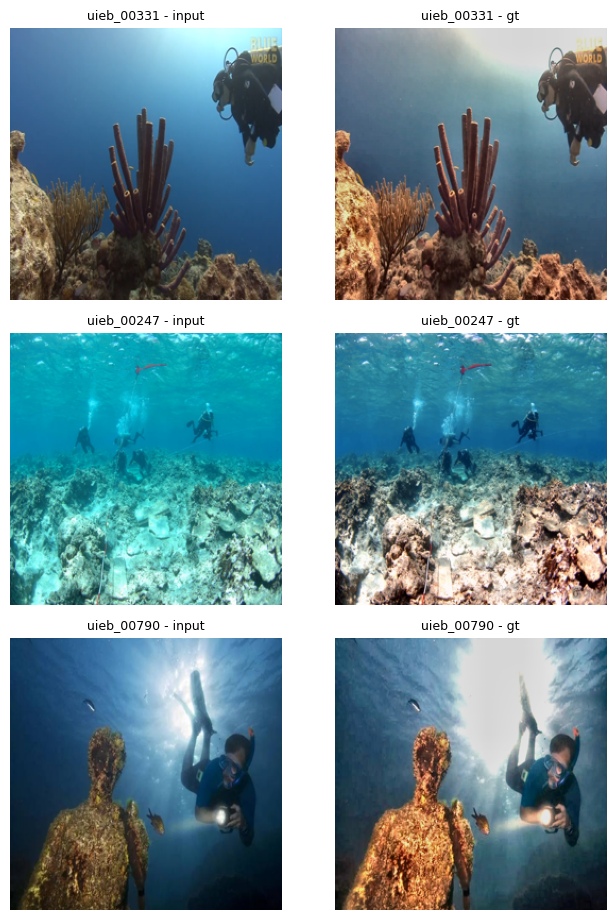

In [17]:
sample = kept.sample(min(3, len(kept)), random_state=SEED)
fig, axes = plt.subplots(len(sample), 2, figsize=(7, 3.1*len(sample)))
if len(sample)==1: axes = np.array([axes])
for r, (_, row) in enumerate(sample.iterrows()):
    for cix, role in enumerate(['input','gt']):
        axes[r,cix].imshow(Image.open(OUT_ROOT/'r256'/role/f'{row.clean_id}.png'))
        axes[r,cix].set_title(f'{row.clean_id} - {role}', fontsize=9); axes[r,cix].axis('off')
plt.tight_layout(); plt.show()


---
## Step 11 — Save as a reusable Kaggle Dataset

1. **Save Version** → *Save & Run All (Commit)*.
2. When it finishes, open the notebook's **Output** tab.
3. **New Dataset** → name it `uieb-clean-sih25243`, keep it **private**.

Then every training notebook just attaches that dataset — no re-running ETL, no re-download.

**Commit to GitHub:** `stats.md`, `manifest.csv` and the three split CSVs. **Never the images.**


In [18]:
print('SUMMARY'); print('='*56)
print(f'  Source               : {KAGGLE_DATASET}')
print(f'  Files scanned        : {len(df_in)+len(df_gt):,}')
print(f'  Matched pairs        : {len(pairs):,}')
print(f'  Rejected             : {int((~pairs.keep).sum()):,}')
print(f'  Final clean pairs    : {len(kept):,}')
print(f'  Challenge (C60)      : {len(chal):,}')
print(f'  Train / Val / Test   : ' + ' / '.join(f'{int((kept.split==s).sum()):,}' for s in ['train','val','test']))
print(f'  LSUI leakage check   : ' + (f'{len(leak_df):,} overlaps' if LEAKAGE_DONE else 'NOT RUN'))
print('='*56)
for d in ['Corrupt / duplicate images removed','Consistent folder structure in place',
          'Splits created and saved','Stats doc written']: print(f'    [x] {d}')
print('='*56); print(f'  Output : {OUT_ROOT}'); print(f'  Reports: {REPORT_DIR}')


SUMMARY
  Source               : naomirory2/uieb-final
  Files scanned        : 1,780
  Matched pairs        : 890
  Rejected             : 10
  Final clean pairs    : 880
  Challenge (C60)      : 60
  Train / Val / Test   : 712 / 79 / 89
  LSUI leakage check   : NOT RUN
    [x] Corrupt / duplicate images removed
    [x] Consistent folder structure in place
    [x] Splits created and saved
    [x] Stats doc written
  Output : /kaggle/working/uieb_clean
  Reports: /kaggle/working/reports


---
---

# PART 2 — Baselines, ANN, CNN & Transformer  (Mid-Term: Weeks 1–8)

**Project:** Underwater Image Enhancement for Maritime Security (SIH25243)  ·  **Dataset:** UIEB, cleaned in Part 1 above (880 pairs → 712 train / 79 val / 89 test, + C60 challenge)

Part 2 covers every Gantt-chart item still due **before the Week-8 mid-term evaluation**, continuing from the Part 1 ETL above. Steps are numbered **M0–M12** so they don't clash with Part 1.

| Gantt item (week) | Where in this notebook |
|---|---|
| Dataset selection, EDA (W1–2) | Part 1 Steps 7–9 + Step M2 (split recap) |
| **Implement 2 ML baseline models** (W1–2) | Step M5 — Ridge polynomial regression, Random Forest |
| Implement deep learning architectures (W4–5) | Step M6 — **ANN** (pixel MLP) · Step M7 — **CNN** (plain residual CNN, U-Net encoder–decoder, GC-U-Net) · Step M7e — **Transformer** (hybrid ViT) |
| Model improvement, hyperparameter tuning, regularization & evaluation (W6–7) | Steps M6–M7 (grid search, global-context and regularization ablations, early stopping) · Steps M8–M10 (evaluation) |
| Mid-term evaluation & presentation (W8) | Step M11 — results tables, figures and an auto-written summary for your slides |

### Compute plan — why the CNN runs on a sample
- **Classical ML + ANN** work on per-pixel feature vectors. They are cheap and use **all 712 training images** in every mode.
- **CNNs** are the expensive part, so `RUN_MODE = 'sample'` (default) trains them on a **random subset of 400 training images, for at most 40 epochs**, with early stopping. On a T4 this takes about 3–4 min per CNN. Evaluation is always on the **full T89 test set at 256×256**, so every model is scored on identical data.
- `RUN_MODE = 'full'` uses all 712 images and up to 120 epochs, for the final report numbers.

### What changed after the first mid-term run
In the first run the CNNs (≈19 dB) lost to the pixel ANN (24.7 dB). Two causes:
1. **Too little training.** 128-px crops, 300 images, 30 epochs, about 30 s per model on a T4. The budget is now much larger.
2. **No global context.** The ANN and ML models are given whole-image colour statistics (mean, std and 1st/99th percentile per channel), which describe the colour cast directly. A CNN looking at a crop has to guess it.

The fix is a third CNN, the **GC-U-Net (global-context U-Net)**. It receives the same 12 whole-image statistics and uses them to predict a per-image colour correction, then refines it spatially with the U-Net (details in Step 7). The plain U-Net stays in as an ablation, so the gain from global context is measured, not assumed.

### Before running (Kaggle)
1. **Accelerator → GPU T4 ×1** (recommended; on CPU the notebook shrinks the CNN budget automatically).
2. **Internet ON** (Part 1 downloads the raw data with `kagglehub`).
3. **Run All.** Part 2 picks up Part 1's output from `/kaggle/working/uieb_clean` automatically. If you saved it as the `uieb-clean-sih25243` dataset and attach that, it uses that instead; if neither exists, it rebuilds the identical split from the raw data.
   Part 1 takes ~2–3 min; Part 2 in sample mode on a T4 takes roughly 25–35 min (mostly the four CNN trainings).

All outputs go to `/kaggle/working/midterm/` (results CSVs, figures, model weights, `midterm_summary.md`).

---
## Step M0 — Setup and configuration

In [19]:
import os, sys, json, time, math, random, warnings, copy
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np, pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import cv2
from scipy import ndimage, stats
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings('ignore')
cv2.setNumThreads(0)

# ================================ CONFIG ================================
RUN_MODE            = 'full'   # 'sample' = quick Kaggle run (default) | 'full' = all 712 train images, long training
PROFILE_OVERRIDES   = {}         # e.g. {'CNN_TRAIN_N': 400, 'EPOCHS': 40} to tweak one setting
CLEAN_ROOT_OVERRIDE = None       # e.g. '/kaggle/input/uieb-clean-sih25243/uieb_clean' (auto-detected if None)
RAW_KAGGLE_DATASET  = 'naomirory2/uieb-final'   # fallback only: rebuild the clean split from raw
SEED                = 42
IMG                 = 256        # every model is evaluated on the 256x256 copies

PROFILES = {
    # CNN_TRAIN_N : training images the CNNs see (None = all 712)
    # CROP        : random-crop size for CNN training (CNNs are fully convolutional, so they still infer at 256)
    # TUNE_*      : budget for each hyper-parameter grid run
    # VAL_EVAL_N  : val images scored after every CNN epoch (None = all 79)
    'sample': dict(CNN_TRAIN_N=400, CROP=256, BATCH=8, EPOCHS=40, PATIENCE=10,
                   TUNE_N=200, TUNE_EPOCHS=10, VAL_EVAL_N=None,
                   PIX_PER_IMG=1000, RIDGE_MAX_SAMPLES=200_000, RF_MAX_SAMPLES=150_000, RF_TREES=50,
                   ANN_EPOCHS=15, ANN_TUNE_EPOCHS=4),
    'full':   dict(CNN_TRAIN_N=None, CROP=256, BATCH=8, EPOCHS=120, PATIENCE=20,
                   TUNE_N=400, TUNE_EPOCHS=15, VAL_EVAL_N=None,
                   PIX_PER_IMG=2000, RIDGE_MAX_SAMPLES=400_000, RF_MAX_SAMPLES=400_000, RF_TREES=100,
                   ANN_EPOCHS=30, ANN_TUNE_EPOCHS=6),
}
CFG = dict(PROFILES[RUN_MODE]); CFG.update(PROFILE_OVERRIDES)

DEVICE  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
if DEVICE.type == 'cpu' and RUN_MODE == 'sample' and not PROFILE_OVERRIDES:
    # no GPU: shrink the CNN budget further so the notebook still finishes in reasonable time
    CFG.update(CNN_TRAIN_N=150, CROP=128, BATCH=16, EPOCHS=15, PATIENCE=5, TUNE_N=80, TUNE_EPOCHS=4, VAL_EVAL_N=25)
    print('!! No GPU detected - CNN budget reduced. Enable "GPU T4 x1" for better CNN results.')

OUT = Path('/kaggle/working/midterm') if Path('/kaggle/working').exists() else Path('./midterm').resolve()
FIG, MODELS = OUT/'figures', OUT/'models'
for d in (OUT, FIG, MODELS): d.mkdir(parents=True, exist_ok=True)

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed()
torch.backends.cudnn.benchmark = True
RUN_STARTED = time.strftime('%Y-%m-%d %H:%M:%S')

print(f'Python {sys.version.split()[0]} | torch {torch.__version__} | device: {DEVICE}'
      + (f' ({torch.cuda.get_device_name(0)})' if DEVICE.type == 'cuda' else ''))
print(f'RUN_MODE = {RUN_MODE!r}')
for k, v in CFG.items(): print(f'   {k:<18} {v}')
print('Outputs ->', OUT)

Python 3.13.16 | torch 2.11.0+cu130 | device: cuda (Tesla T4)
RUN_MODE = 'full'
   CNN_TRAIN_N        None
   CROP               256
   BATCH              8
   EPOCHS             120
   PATIENCE           20
   TUNE_N             400
   TUNE_EPOCHS        15
   VAL_EVAL_N         None
   PIX_PER_IMG        2000
   RIDGE_MAX_SAMPLES  400000
   RF_MAX_SAMPLES     400000
   RF_TREES           100
   ANN_EPOCHS         30
   ANN_TUNE_EPOCHS    6
Outputs -> /kaggle/working/midterm


---
## Step M1 — Load the cleaned UIEB split

Looks for the Part 1 output (`splits/train.csv` + `r256/`) under `/kaggle/input` and `/kaggle/working`. If it isn't attached, it **rebuilds the same split from the raw dataset** using Part 1's rules: the same filename pairing, dHash near-duplicate removal (threshold 5), seed-42 permutation and 89 / 79 / 712 sizes.

In [20]:
def find_clean_root():
    if CLEAN_ROOT_OVERRIDE: return Path(CLEAN_ROOT_OVERRIDE)
    for base in [Path('/kaggle/input'), Path('/kaggle/working'), Path('.')]:
        if not base.exists(): continue
        for dirpath, dirnames, _ in os.walk(base):
            d = Path(dirpath)
            if (d/'splits'/'train.csv').exists() and (d/'r256'/'input').is_dir():
                return d
            if len(d.relative_to(base).parts) >= 5 or d.name in ('input', 'gt', 'full', 'r256', 'challenge'):
                dirnames[:] = []           # don't descend into image folders
    return None

def load_rgb(p):
    with Image.open(p) as im:
        im = im.convert('RGB')
        if im.size != (IMG, IMG): im = im.resize((IMG, IMG), Image.BICUBIC)
        return np.asarray(im, dtype=np.uint8)

def load_many(paths):
    with ThreadPoolExecutor(max_workers=8) as ex: return np.stack(list(ex.map(load_rgb, paths)))

def rebuild_from_raw():
    """Re-creates Part 1's clean split in memory (same pairing, dedup and seed)."""
    import kagglehub
    root = Path(kagglehub.dataset_download(RAW_KAGGLE_DATASET))
    def find(name): return next(p for p in root.rglob(name) if p.is_dir())
    raw_d, ref_d, chal_d = find('raw-890'), find('reference-890'), find('challenging-60')
    ext = {'.png', '.jpg', '.jpeg', '.bmp'}
    ls = lambda d: {f.stem: f for f in sorted(d.iterdir()) if f.suffix.lower() in ext}
    R, G = ls(raw_d), ls(ref_d)
    common = sorted(set(R) & set(G))
    def dh(p):
        with Image.open(p) as im:
            a = np.asarray(im.convert('L').resize((9, 8), Image.LANCZOS), dtype=np.int16)
        return np.packbits((a[:, 1:] > a[:, :-1]).flatten())
    with ThreadPoolExecutor(max_workers=8) as ex: H = np.stack(list(ex.map(dh, [R[s] for s in common])))
    POP = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
    D = POP[np.bitwise_xor(H[:, None, :], H[None, :, :])].sum(2)
    drop = set()
    for i, j in zip(*np.where(D <= 5)):
        if i < j and common[i] not in drop and common[j] not in drop: drop.add(common[j])
    kept = [s for s in common if s not in drop]
    df = pd.DataFrame({'clean_id': [f'uieb_{i:05d}' for i in range(len(kept))], 'stem': kept})
    n = len(df); idx = np.random.default_rng(SEED).permutation(n)
    n_test = min(90, max(1, int(round(n * 90 / 890))))
    rest = idx[n_test:]; n_val = int(round(len(rest) * 0.10))
    df['split'] = 'train'
    df.loc[df.index[rest[:n_val]], 'split'] = 'val'
    df.loc[df.index[idx[:n_test]], 'split'] = 'test'
    df['in_path'] = [str(R[s]) for s in df.stem]; df['gt_path'] = [str(G[s]) for s in df.stem]
    chal_files = sorted(f for f in chal_d.iterdir() if f.suffix.lower() in ext)
    chal = pd.DataFrame({'clean_id': [f'uieb_chal_{i:03d}' for i in range(len(chal_files))],
                         'path': [str(f) for f in chal_files]})
    print(f'Rebuilt from raw: {len(common)} pairs, {len(drop)} near-duplicates removed, {n} kept')
    return df, chal

CLEAN_ROOT = find_clean_root()
if CLEAN_ROOT is not None:
    print('Using cleaned dataset:', CLEAN_ROOT)
    sp = CLEAN_ROOT/'splits'
    meta = pd.concat([pd.read_csv(sp/f'{s}.csv') for s in ['train', 'val', 'test']], ignore_index=True)
    meta['in_path'] = [str(CLEAN_ROOT/'r256'/'input'/f'{c}.png') for c in meta.clean_id]
    meta['gt_path'] = [str(CLEAN_ROOT/'r256'/'gt'/f'{c}.png') for c in meta.clean_id]
    chal = pd.read_csv(sp/'challenge.csv') if (sp/'challenge.csv').exists() else pd.DataFrame(columns=['clean_id'])
    chal['path'] = [str(CLEAN_ROOT/'challenge'/'r256'/f'{c}.png') for c in chal.clean_id]
    DATA_SOURCE = f'cleaned dataset at {CLEAN_ROOT}'
else:
    print('Cleaned dataset not attached -> rebuilding from', RAW_KAGGLE_DATASET, '(needs Internet ON)')
    try:
        meta, chal = rebuild_from_raw()
    except Exception as e:
        raise SystemExit(f'STOP: could not find or rebuild the data ({type(e).__name__}: {e}). '
                         'Attach uieb-clean-sih25243 or turn Internet ON.')
    DATA_SOURCE = f'rebuilt in memory from {RAW_KAGGLE_DATASET}'

t0 = time.time()
split = {}
for s in ['train', 'val', 'test']:
    m = meta[meta.split == s].reset_index(drop=True)
    split[s] = dict(meta=m, X=load_many(m.in_path.tolist()), Y=load_many(m.gt_path.tolist()))
X_ch = load_many(chal.path.tolist()) if len(chal) else np.zeros((0, IMG, IMG, 3), np.uint8)
X_tr, Y_tr = split['train']['X'], split['train']['Y']
X_va, Y_va = split['val']['X'],   split['val']['Y']
X_te, Y_te = split['test']['X'],  split['test']['Y']
print(f'Loaded in {time.time()-t0:.1f}s | train {len(X_tr)} | val {len(X_va)} | test {len(X_te)} | challenge {len(X_ch)}')
mb = sum(a.nbytes for a in [X_tr, Y_tr, X_va, Y_va, X_te, Y_te, X_ch]) / 1e6
print(f'RAM used by images: {mb:.0f} MB')

Using cleaned dataset: /kaggle/working/uieb_clean
Loaded in 3.0s | train 712 | val 79 | test 89 | challenge 60
RAM used by images: 358 MB


---
## Step M2 — EDA recap (mid-term figure)

Full EDA is in Part 1 (Steps 7–7b). Here we only confirm that **train / val / test are statistically comparable** (similar colour cast and similar raw-vs-reference gap), and save a sample-pairs figure for the slides.

split   n  raw_R  raw_G  raw_B  raw_vs_ref_PSNR
train 712  68.84 125.41 126.20            17.52
  val  79  63.92 121.70 127.81            17.29
 test  89  71.05 127.47 125.70            17.22


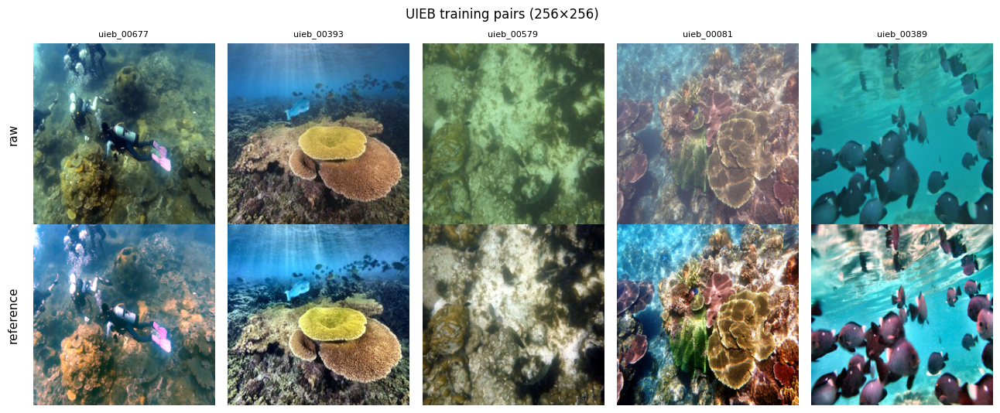

In [21]:
def psnr_u8(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return 99.0 if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)

rows = []
for s in ['train', 'val', 'test']:
    X, Y = split[s]['X'], split[s]['Y']
    m = X.reshape(len(X), -1, 3).mean(1)
    rows.append({'split': s, 'n': len(X), 'raw_R': m[:, 0].mean(), 'raw_G': m[:, 1].mean(), 'raw_B': m[:, 2].mean(),
                 'raw_vs_ref_PSNR': np.mean([psnr_u8(x, y) for x, y in zip(X, Y)])})
split_stats = pd.DataFrame(rows).round(2)
print(split_stats.to_string(index=False))
split_stats.to_csv(OUT/'split_stats.csv', index=False)

rng = np.random.default_rng(SEED)
pick = rng.choice(len(X_tr), size=min(5, len(X_tr)), replace=False)
fig, ax = plt.subplots(2, len(pick), figsize=(2.6*len(pick), 5.4))
ax = np.atleast_2d(ax).reshape(2, -1)
for c, i in enumerate(pick):
    ax[0, c].imshow(X_tr[i]); ax[1, c].imshow(Y_tr[i])
    ax[0, c].set_title(split['train']['meta'].clean_id[i], fontsize=8)
    for r in (0, 1): ax[r, c].axis('off')
ax[0, 0].text(-20, IMG/2, 'raw', rotation=90, va='center', ha='right', fontsize=11)
ax[1, 0].text(-20, IMG/2, 'reference', rotation=90, va='center', ha='right', fontsize=11)
plt.suptitle('UIEB training pairs (256×256)'); plt.tight_layout()
plt.savefig(FIG/'01_sample_pairs.png', dpi=130, bbox_inches='tight'); plt.show()

---
## Step M3 — Evaluation toolkit

| Metric | Type | Higher is better | Used on |
|---|---|---|---|
| **PSNR** (dB) | full-reference, pixel fidelity | ✓ | T89 test |
| **SSIM** | full-reference, structure | ✓ | T89 test |
| **UIQM** (Panetta et al., 2016) | no-reference, underwater-specific (colour + sharpness + contrast) | ✓ | T89 + C60 |
| **UCIQE** (Yang & Sowmya, 2015) | no-reference, underwater-specific (chroma + contrast + saturation) | ✓ | T89 + C60 |

**Note:** UIQM/UCIQE implementations differ slightly between papers, so use these numbers to **compare methods inside this project**, not against numbers from other papers.

In [22]:
from skimage.metrics import structural_similarity as _ssim

def ssim_u8(a, b): return float(_ssim(a, b, channel_axis=2, data_range=255))

def uciqe(img):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB).astype(np.float64)
    L = lab[..., 0] * 100 / 255; a = lab[..., 1] - 128; b = lab[..., 2] - 128
    chroma = np.sqrt(a ** 2 + b ** 2)
    Ls = np.sort(L.ravel()); k = max(1, int(0.01 * Ls.size))
    con_l = (Ls[-k:].mean() - Ls[:k].mean()) / 100
    sat = chroma / np.maximum(np.sqrt(chroma ** 2 + L ** 2), 1e-6)
    return float(0.4680 * chroma.std() / 100 + 0.2745 * con_l + 0.2576 * sat.mean())

def _trim_mean(x, a=0.1):
    x = np.sort(x.ravel()); k = len(x); lo, hi = int(math.ceil(a * k)), int(math.floor(a * k))
    return x[lo:k - hi].mean()

def _uicm(x):
    R, G, B = x[..., 0], x[..., 1], x[..., 2]
    RG, YB = R - G, (R + G) / 2 - B
    mrg, myb = _trim_mean(RG), _trim_mean(YB)
    srg, syb = np.mean((RG - mrg) ** 2), np.mean((YB - myb) ** 2)
    return -0.0268 * np.sqrt(mrg ** 2 + myb ** 2) + 0.1586 * np.sqrt(srg + syb)

def _blocks(ch, ws):
    k2, k1 = ch.shape[0] // ws, ch.shape[1] // ws
    return ch[:k2 * ws, :k1 * ws].reshape(k2, ws, k1, ws, *ch.shape[2:]), k1 * k2

def _eme(ch, ws=10):
    b, n = _blocks(ch, ws); mx, mn = b.max(axis=(1, 3)), b.min(axis=(1, 3))
    ok = (mx > 0) & (mn > 0); v = np.zeros_like(mx); v[ok] = np.log(mx[ok] / mn[ok])
    return 2.0 / n * v.sum()

def _uism(x):
    out = 0.0
    for ch, lam in zip(range(3), (0.299, 0.587, 0.144)):
        c = x[..., ch]; mag = np.hypot(ndimage.sobel(c, 0), ndimage.sobel(c, 1))
        mag = mag * (255.0 / mag.max()) if mag.max() > 0 else mag
        out += lam * _eme(mag * c)
    return out

def _uiconm(x, ws=10):
    b, n = _blocks(x, ws); mx, mn = b.max(axis=(1, 3, 4)), b.min(axis=(1, 3, 4))
    top, bot = mx - mn, mx + mn; ok = (top > 0) & (bot > 0)
    r = np.zeros_like(top); r[ok] = top[ok] / bot[ok]
    v = np.zeros_like(top); v[ok] = r[ok] * np.log(r[ok])
    return -1.0 / n * v.sum()

def uiqm(img):
    x = img.astype(np.float64)
    return float(0.0282 * _uicm(x) + 0.2953 * _uism(x) + 3.5753 * _uiconm(x))

def evaluate(name, fn, X, Y=None, ids=None):
    """Runs fn on every image, returns a per-image metrics DataFrame plus the predictions."""
    recs, preds = [], []
    for i in range(len(X)):
        t0 = time.perf_counter(); p = fn(X[i]); dt = (time.perf_counter() - t0) * 1000
        r = {'method': name, 'id': ids[i] if ids is not None else i, 'ms': dt, 'UIQM': uiqm(p), 'UCIQE': uciqe(p)}
        if Y is not None: r.update(PSNR=psnr_u8(p, Y[i]), SSIM=ssim_u8(p, Y[i]))
        recs.append(r); preds.append(p)
    return pd.DataFrame(recs), np.stack(preds)

print(f'Sanity: raw vs reference on test  PSNR {np.mean([psnr_u8(x, y) for x, y in zip(X_te, Y_te)]):.2f} dB')
print(f'UIQM  raw {np.mean([uiqm(x) for x in X_te[:20]]):.3f} | reference {np.mean([uiqm(y) for y in Y_te[:20]]):.3f}   (first 20 test images)')
print(f'UCIQE raw {np.mean([uciqe(x) for x in X_te[:20]]):.3f} | reference {np.mean([uciqe(y) for y in Y_te[:20]]):.3f}')

Sanity: raw vs reference on test  PSNR 17.22 dB
UIQM  raw 2.844 | reference 3.206   (first 20 test images)
UCIQE raw 0.310 | reference 0.410


---
## Step M4 — Classical reference points (no learning)

Not ML models. They are the lower bounds every learned model must beat:
- **Raw input** — no enhancement.
- **Gray-World** — global white balance; removes the blue-green cast.
- **Gray-World + CLAHE** — white balance followed by local contrast equalisation on the L channel.

In [23]:
def identity(x): return x

def gray_world(x):
    f = x.astype(np.float32); m = f.reshape(-1, 3).mean(0)
    return np.clip(f * (m.mean() / np.maximum(m, 1e-6)), 0, 255).astype(np.uint8)

_clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
def gw_clahe(x):
    lab = cv2.cvtColor(gray_world(x), cv2.COLOR_RGB2LAB)
    lab[..., 0] = _clahe.apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

PREDICTORS = {'Raw input': identity, 'Gray-World': gray_world, 'Gray-World + CLAHE': gw_clahe}
FAMILY     = {'Raw input': 'reference', 'Gray-World': 'classical', 'Gray-World + CLAHE': 'classical'}
PARAMS     = {k: 0 for k in PREDICTORS}
for k, fn in PREDICTORS.items():
    df, _ = evaluate(k, fn, X_va, Y_va)
    print(f'{k:<20} val PSNR {df.PSNR.mean():6.2f} | SSIM {df.SSIM.mean():.3f}')

Raw input            val PSNR  17.29 | SSIM 0.753
Gray-World           val PSNR  16.35 | SSIM 0.747
Gray-World + CLAHE   val PSNR  16.86 | SSIM 0.802


---
## Step M5 — Two ML baselines (Gantt: *Implement 2 ML baseline models*)

Classical ML can't take a whole image as input, so each pixel becomes a **21-dimensional hand-crafted feature vector**:

| Features | Count | Captures |
|---|---|---|
| pixel RGB | 3 | the colour to correct |
| 7×7 local mean RGB, 7×7 local std RGB | 6 | neighbourhood / texture |
| image-level mean, std, 1st & 99th percentile per channel | 12 | the global colour cast and haze level |

The target is the reference pixel's RGB. Every model trains on `PIX_PER_IMG` random pixels from **each of the 712 training images**.
The **ANN in Step M6 uses exactly the same features**, so ML vs ANN is a fair comparison. The CNNs in Step M7 learn their own features from raw pixels.

1. **Ridge regression on degree-2 polynomial features** — a learned, non-linear colour-correction matrix.
2. **Random Forest regressor** (multi-output) — a non-parametric, piecewise mapping.

In [24]:
N_FEAT, N_GLOBAL = 21, 12
def global_stats(img):
    """12 whole-image statistics: per-channel mean, std, 1st and 99th percentile (shared by ML, ANN and GC-U-Net)."""
    flat = img.reshape(-1, 3).astype(np.float32) / 255.0
    return np.concatenate([flat.mean(0), flat.std(0), np.percentile(flat, 1, axis=0),
                           np.percentile(flat, 99, axis=0)]).astype(np.float32)

def pixel_features(img):
    f = img.astype(np.float32) / 255.0
    mu = cv2.blur(f, (7, 7)); sd = np.sqrt(np.maximum(cv2.blur(f * f, (7, 7)) - mu * mu, 0))
    flat = f.reshape(-1, 3); g = global_stats(img)
    return np.concatenate([flat, mu.reshape(-1, 3), sd.reshape(-1, 3),
                           np.broadcast_to(g, (flat.shape[0], 12))], 1).astype(np.float32)

def sample_pixels(X, Y, per_img, seed):
    r = np.random.default_rng(seed); Fs, Ts = [], []
    for x, y in zip(X, Y):
        idx = r.choice(IMG * IMG, size=min(per_img, IMG * IMG), replace=False)
        Fs.append(pixel_features(x)[idx]); Ts.append(y.reshape(-1, 3)[idx].astype(np.float32) / 255.0)
    return np.concatenate(Fs), np.concatenate(Ts)

t0 = time.time()
F_tr, T_tr = sample_pixels(X_tr, Y_tr, CFG['PIX_PER_IMG'], SEED)
F_va, T_va = sample_pixels(X_va, Y_va, CFG['PIX_PER_IMG'], SEED + 1)
print(f'Pixel dataset: train {F_tr.shape} | val {F_va.shape} | built in {time.time()-t0:.1f}s')
pix_psnr = lambda pred, tgt: 10 * np.log10(1.0 / np.mean((np.clip(pred, 0, 1) - tgt) ** 2))

def make_pixel_predictor(predict_rows):
    def fn(img):
        out = predict_rows(pixel_features(img))
        return (np.clip(out, 0, 1).reshape(IMG, IMG, 3) * 255 + 0.5).astype(np.uint8)
    return fn

Pixel dataset: train (1424000, 21) | val (158000, 21) | built in 10.3s


### M5a — ML baseline 1: Ridge polynomial regression (α tuned on validation pixels)

In [25]:
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

r = np.random.default_rng(SEED)
sub = r.choice(len(F_tr), size=min(CFG['RIDGE_MAX_SAMPLES'], len(F_tr)), replace=False)
scaler = StandardScaler().fit(F_tr[sub]); poly = PolynomialFeatures(2, include_bias=False)
P_tr = poly.fit_transform(scaler.transform(F_tr[sub])).astype(np.float32)
P_va = poly.transform(scaler.transform(F_va)).astype(np.float32)
print(f'Polynomial features: {P_tr.shape[1]}')

ridge_tune = []
for alpha in [0.01, 1.0, 100.0, 1000.0]:
    t0 = time.time(); m = Ridge(alpha=alpha).fit(P_tr, T_tr[sub])
    ridge_tune.append({'alpha': alpha, 'val_pixel_PSNR': pix_psnr(m.predict(P_va), T_va), 'fit_s': time.time() - t0})
ridge_tune = pd.DataFrame(ridge_tune); print(ridge_tune.round(3).to_string(index=False))
best_alpha = float(ridge_tune.sort_values('val_pixel_PSNR', ascending=False).alpha.iloc[0])
ridge = Ridge(alpha=best_alpha).fit(P_tr, T_tr[sub]); del P_tr
print(f'-> chosen alpha = {best_alpha}')

PREDICTORS['ML-1 Ridge (poly-2)'] = make_pixel_predictor(
    lambda Fx: ridge.predict(poly.transform(scaler.transform(Fx)).astype(np.float32)))
FAMILY['ML-1 Ridge (poly-2)'] = 'ML baseline'; PARAMS['ML-1 Ridge (poly-2)'] = int(ridge.coef_.size + ridge.intercept_.size)

Polynomial features: 252
  alpha  val_pixel_PSNR  fit_s
   0.01       21.615999  0.770
   1.00       21.615999  0.765
 100.00       21.618000  0.757
1000.00       21.615999  0.753
-> chosen alpha = 100.0


### M5b — ML baseline 2: Random Forest (max_depth tuned on validation pixels)

In [26]:
sub = r.choice(len(F_tr), size=min(CFG['RF_MAX_SAMPLES'], len(F_tr)), replace=False)
tsub = sub[:max(1, len(sub) // 3)]
rf_tune = []
for depth in [12, 20]:
    t0 = time.time()
    m = RandomForestRegressor(n_estimators=20, max_depth=depth, min_samples_leaf=5,
                              n_jobs=-1, random_state=SEED).fit(F_tr[tsub], T_tr[tsub])
    rf_tune.append({'max_depth': depth, 'val_pixel_PSNR': pix_psnr(m.predict(F_va), T_va), 'fit_s': time.time() - t0})
rf_tune = pd.DataFrame(rf_tune); print(rf_tune.round(3).to_string(index=False))
best_depth = int(rf_tune.sort_values('val_pixel_PSNR', ascending=False).max_depth.iloc[0])

t0 = time.time()
rf = RandomForestRegressor(n_estimators=CFG['RF_TREES'], max_depth=best_depth, min_samples_leaf=5,
                           max_features=0.6, n_jobs=-1, random_state=SEED).fit(F_tr[sub], T_tr[sub])
print(f'-> chosen max_depth = {best_depth} | final RF ({CFG["RF_TREES"]} trees, {len(sub):,} pixels) fit in {time.time()-t0:.1f}s')
print(f'   val pixel PSNR {pix_psnr(rf.predict(F_va), T_va):.2f} dB')
imp = pd.Series(rf.feature_importances_, index=
      ['R', 'G', 'B', 'muR', 'muG', 'muB', 'sdR', 'sdG', 'sdB', 'gmR', 'gmG', 'gmB', 'gsR', 'gsG', 'gsB',
       'p1R', 'p1G', 'p1B', 'p99R', 'p99G', 'p99B']).sort_values(ascending=False)
print('Top-8 RF feature importances:', ', '.join(f'{k} {v:.3f}' for k, v in imp.head(8).items()))

PREDICTORS['ML-2 Random Forest'] = make_pixel_predictor(rf.predict)
FAMILY['ML-2 Random Forest'] = 'ML baseline'
PARAMS['ML-2 Random Forest'] = int(sum(e.tree_.node_count for e in rf.estimators_))   # tree nodes, not weights

 max_depth  val_pixel_PSNR  fit_s
        12          19.962 12.589
        20          20.190 15.707
-> chosen max_depth = 20 | final RF (100 trees, 400,000 pixels) fit in 140.2s
   val pixel PSNR 20.56 dB
Top-8 RF feature importances: G 0.381, B 0.141, muG 0.116, R 0.077, gmG 0.061, muB 0.039, p1G 0.023, muR 0.020


---
## Step M6 — ANN: pixel-wise multilayer perceptron

A fully-connected network on the **same 21 features**, predicting a residual correction on top of the input pixel (output = input RGB + MLP(features)). The last layer is zero-initialised, so training starts from the identity mapping.

- **Tuning:** grid over hidden layers × dropout, short runs, scored by validation pixel PSNR.
- **Regularization:** dropout, AdamW weight decay, early stopping on validation.

Cheap enough for CPU — it trains on all 712 images in every mode.

In [27]:
FEAT_MU = torch.tensor(F_tr.mean(0)); FEAT_SD = torch.tensor(F_tr.std(0) + 1e-6)

class PixelMLP(nn.Module):
    def __init__(self, hidden=(256, 128, 64), drop=0.1):
        super().__init__()
        self.register_buffer('mu', FEAT_MU.clone()); self.register_buffer('sd', FEAT_SD.clone())
        layers, d = [], N_FEAT
        for h in hidden: layers += [nn.Linear(d, h), nn.GELU(), nn.Dropout(drop)]; d = h
        self.body = nn.Sequential(*layers); self.head = nn.Linear(d, 3)
        nn.init.zeros_(self.head.weight); nn.init.zeros_(self.head.bias)
    def forward(self, f):
        return f[:, :3] + self.head(self.body((f - self.mu) / self.sd))

Ft_tr, Tt_tr = torch.from_numpy(F_tr).to(DEVICE), torch.from_numpy(T_tr).to(DEVICE)
Ft_va, Tt_va = torch.from_numpy(F_va).to(DEVICE), torch.from_numpy(T_va).to(DEVICE)

@torch.no_grad()
def mlp_val_psnr(model):
    model.eval(); out = torch.cat([model(Ft_va[i:i + 65536]) for i in range(0, len(Ft_va), 65536)])
    return float(10 * torch.log10(1.0 / F.mse_loss(out.clamp(0, 1), Tt_va)))

def train_mlp(hidden, drop, lr=1e-3, wd=1e-4, epochs=10, patience=4, bs=4096, verbose=False):
    set_seed(); model = PixelMLP(hidden, drop).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    best, best_state, bad, hist = -1e9, None, 0, []
    for ep in range(1, epochs + 1):
        model.train(); perm = torch.randperm(len(Ft_tr), device=DEVICE); tot = 0.0
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]; loss = F.l1_loss(model(Ft_tr[b]), Tt_tr[b])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); tot += loss.item() * len(b)
        sched.step(); v = mlp_val_psnr(model); hist.append({'epoch': ep, 'train_L1': tot / len(perm), 'val_pixel_PSNR': v})
        if verbose: print(f'   ep {ep:>3} | train L1 {tot/len(perm):.4f} | val pixel PSNR {v:.2f}')
        if v > best: best, best_state, bad = v, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state); return model, best, pd.DataFrame(hist)

ann_tune = []
for hidden in [(128, 64), (256, 128, 64)]:
    for drop in [0.0, 0.1]: ##dropout meaning makes random vlaues 0 prevents the network from memorising
        t0 = time.time(); _, v, _ = train_mlp(hidden, drop, epochs=CFG['ANN_TUNE_EPOCHS'], patience=99)
        ann_tune.append({'hidden': str(hidden), 'dropout': drop, 'val_pixel_PSNR': v, 'time_s': time.time() - t0})
        print(f'  hidden={str(hidden):<16} dropout={drop:<4} -> val pixel PSNR {v:.3f}')
ann_tune = pd.DataFrame(ann_tune).sort_values('val_pixel_PSNR', ascending=False)
ann_tune.to_csv(OUT/'tuning_ann.csv', index=False)
best_ann = ann_tune.iloc[0]; ANN_HIDDEN = eval(best_ann.hidden); ANN_DROP = float(best_ann.dropout)
print(f'-> best ANN config: hidden={ANN_HIDDEN}, dropout={ANN_DROP}\n\nFinal ANN training:')

t0 = time.time()
ann, ann_best, ann_hist = train_mlp(ANN_HIDDEN, ANN_DROP, epochs=CFG['ANN_EPOCHS'], patience=4, verbose=True)
print(f'ANN trained in {time.time()-t0:.1f}s | best val pixel PSNR {ann_best:.2f} dB')
torch.save(ann.state_dict(), MODELS/'ann_pixel_mlp.pt')

@torch.no_grad()
def ann_rows(Fx):
    ann.eval(); return ann(torch.from_numpy(Fx).to(DEVICE)).float().cpu().numpy()
PREDICTORS['ANN (pixel MLP)'] = make_pixel_predictor(ann_rows)
FAMILY['ANN (pixel MLP)'] = 'deep learning'; PARAMS['ANN (pixel MLP)'] = sum(p.numel() for p in ann.parameters())
del Ft_tr, Tt_tr

  hidden=(128, 64)        dropout=0.0  -> val pixel PSNR 22.226
  hidden=(128, 64)        dropout=0.1  -> val pixel PSNR 22.330
  hidden=(256, 128, 64)   dropout=0.0  -> val pixel PSNR 22.217
  hidden=(256, 128, 64)   dropout=0.1  -> val pixel PSNR 22.304
-> best ANN config: hidden=(128, 64), dropout=0.1

Final ANN training:
   ep   1 | train L1 0.0586 | val pixel PSNR 21.99
   ep   2 | train L1 0.0507 | val pixel PSNR 22.32
   ep   3 | train L1 0.0487 | val pixel PSNR 22.32
   ep   4 | train L1 0.0472 | val pixel PSNR 22.22
   ep   5 | train L1 0.0460 | val pixel PSNR 22.22
   ep   6 | train L1 0.0450 | val pixel PSNR 21.93
ANN trained in 3.9s | best val pixel PSNR 22.32 dB


---
## Step M7 — CNNs (trained on a sample; see the compute plan at the top)

Three architectures. All of them predict a **residual** on top of the input and are fully convolutional:

| Model | Idea | Sees the global colour cast? |
|---|---|---|
| **Plain CNN** | 8 conv layers at full resolution (UWCNN-style), ~17 px receptive field | ✗ local only |
| **U-Net** | encoder–decoder (convolutional autoencoder) with skip connections, 3 down-samplings | only through its receptive field |
| **GC-U-Net** (proposed) | U-Net + the 12 whole-image colour statistics, used three ways: (a) a small MLP predicts a **per-image 3×3 colour matrix + offset**, applied to every pixel first (a learned white balance); (b) the statistics are extra input channels; (c) an MLP **FiLM-modulates** the bottleneck (`h·(1+γ) + β`). The U-Net then predicts a residual on top of the colour-corrected image. | ✓ explicitly |

The statistics are always computed on the **full 256×256 image**, even when training on crops, so the model sees the true global cast.

**Loss:** L1 + 0.2·(1 − SSIM) — L1 for colour fidelity, SSIM for structure.
**Optimiser:** AdamW + cosine LR schedule + 1-epoch warm-up; mixed precision on GPU.

- **M7a** tunes the GC-U-Net (learning rate × width).
- **M7b** runs a **regularization ablation** on it.
- **M7c** trains the plain U-Net, so the gain from global context is measured.
- **M7d** trains the plain CNN.

**Divergence guard** (added after the full run, where the unregularized GC-U-Net hit NaN around epoch 16 and never recovered): a batch whose loss is not finite is skipped, and if more than half of an epoch's batches are skipped or validation PSNR falls more than 5 dB below the best so far, the best weights are restored and the learning rate is halved. The message `diverged ... -> best weights restored` in the training log shows when it fired.

In [28]:
G_tr = np.stack([global_stats(x) for x in X_tr])
G_MU, G_SD = torch.tensor(G_tr.mean(0)), torch.tensor(G_tr.std(0) + 1e-6)

class PairCrops(Dataset):
    def __init__(self, X, Y, G, ids, crop, aug):
        self.X, self.Y, self.G, self.ids, self.crop, self.aug = X, Y, G, np.asarray(ids), crop, aug
    def __len__(self): return len(self.ids)
    def __getitem__(self, k):
        i = self.ids[k]; x, y = self.X[i], self.Y[i]; c = self.crop
        if c < IMG:
            if self.aug: t, l = np.random.randint(0, IMG - c + 1, size=2)
            else: t = l = (IMG - c) // 2
            x, y = x[t:t + c, l:l + c], y[t:t + c, l:l + c]
        if self.aug and np.random.rand() < 0.5: x, y = x[:, ::-1], y[:, ::-1]   # horizontal flip only; a vertical
        to_t = lambda a: torch.from_numpy(np.ascontiguousarray(a)).permute(2, 0, 1).float().div(255)  # flip would put
        return to_t(x), to_t(y), torch.from_numpy(self.G[i])                     # the light source below the scene

def conv_block(i, o, drop=0.0):
    layers = [nn.Conv2d(i, o, 3, padding=1), nn.LeakyReLU(0.2, inplace=True)]
    if drop > 0: layers.append(nn.Dropout2d(drop))
    layers += [nn.Conv2d(o, o, 3, padding=1), nn.LeakyReLU(0.2, inplace=True)]
    return nn.Sequential(*layers)

class UNet(nn.Module):
    """U-Net encoder-decoder. global_context=True turns it into the GC-U-Net."""
    def __init__(self, base=32, drop=0.0, global_context=False):
        super().__init__(); c = base; self.gc = global_context
        n_in = 3 + (N_GLOBAL if self.gc else 0)
        self.e1, self.e2, self.e3 = conv_block(n_in, c), conv_block(c, 2 * c), conv_block(2 * c, 4 * c)
        self.bott = conv_block(4 * c, 8 * c, drop)
        self.d3, self.d2, self.d1 = conv_block(12 * c, 4 * c), conv_block(6 * c, 2 * c), conv_block(3 * c, c)
        self.out = nn.Conv2d(c, 3, 1); nn.init.zeros_(self.out.weight); nn.init.zeros_(self.out.bias)
        if self.gc:
            self.register_buffer('g_mu', G_MU.clone()); self.register_buffer('g_sd', G_SD.clone())
            # (1) global colour-correction head: per-image 3x3 colour matrix + offset, predicted from the statistics
            self.cc = nn.Sequential(nn.Linear(N_GLOBAL, 64), nn.GELU(), nn.Linear(64, 64), nn.GELU(), nn.Linear(64, 12))
            # (2) FiLM: per-image scale/shift of the bottleneck features
            self.film = nn.Sequential(nn.Linear(N_GLOBAL, 128), nn.GELU(), nn.Linear(128, 16 * c))
            for head in (self.cc, self.film):                       # zero-init: the model starts as the identity
                nn.init.zeros_(head[-1].weight); nn.init.zeros_(head[-1].bias)
    def forward(self, x, g=None):
        up = lambda t: F.interpolate(t, scale_factor=2, mode='bilinear', align_corners=False)
        base, inp = x, x
        if self.gc:
            gz = ((g.float() - self.g_mu) / self.g_sd)
            p = self.cc(gz).float()
            M = torch.eye(3, device=x.device)[None] + p[:, :9].view(-1, 3, 3)
            base = (torch.einsum('bij,bjhw->bihw', M, x.float()) + p[:, 9:, None, None]).to(x.dtype)
            inp = torch.cat([base, gz.to(x.dtype)[:, :, None, None].expand(-1, -1, x.shape[2], x.shape[3])], 1)
        e1 = self.e1(inp); e2 = self.e2(F.max_pool2d(e1, 2)); e3 = self.e3(F.max_pool2d(e2, 2))
        b = self.bott(F.max_pool2d(e3, 2))
        if self.gc:
            gamma, beta = self.film(gz).to(b.dtype).chunk(2, dim=1)
            b = b * (1 + gamma[:, :, None, None]) + beta[:, :, None, None]
        d3 = self.d3(torch.cat([up(b), e3], 1)); d2 = self.d2(torch.cat([up(d3), e2], 1))
        d1 = self.d1(torch.cat([up(d2), e1], 1))
        return base + self.out(d1)

class PlainCNN(nn.Module):
    def __init__(self, width=32, depth=8):
        super().__init__()
        layers = [nn.Conv2d(3, width, 3, padding=1), nn.LeakyReLU(0.2, inplace=True)]
        for _ in range(depth - 2): layers += [nn.Conv2d(width, width, 3, padding=1), nn.LeakyReLU(0.2, inplace=True)]
        last = nn.Conv2d(width, 3, 3, padding=1); nn.init.zeros_(last.weight); nn.init.zeros_(last.bias)
        self.net = nn.Sequential(*layers, last)
    def forward(self, x, g=None): return x + self.net(x)

_WIN = None
def ssim_t(x, y):
    global _WIN
    if _WIN is None or _WIN.device != x.device:
        g = torch.exp(-(torch.arange(11, dtype=torch.float32) - 5) ** 2 / (2 * 1.5 ** 2)); g = g / g.sum()
        _WIN = (g[:, None] * g[None, :])[None, None].repeat(3, 1, 1, 1).to(x.device)
    C1, C2 = 0.01 ** 2, 0.03 ** 2; cv = lambda t: F.conv2d(t, _WIN, padding=5, groups=3)
    mx, my = cv(x), cv(y); sxx, syy, sxy = cv(x * x) - mx ** 2, cv(y * y) - my ** 2, cv(x * y) - mx * my
    return (((2 * mx * my + C1) * (2 * sxy + C2)) / ((mx ** 2 + my ** 2 + C1) * (sxx + syy + C2))).mean()

def cnn_loss(p, y): p = p.float(); return F.l1_loss(p, y) + 0.2 * (1 - ssim_t(p, y))

@torch.no_grad()
def cnn_predict(model, X, bs=8):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = X[i:i + bs]
        x = torch.from_numpy(xb).permute(0, 3, 1, 2).float().div(255).to(DEVICE)
        g = torch.from_numpy(np.stack([global_stats(im) for im in xb])).to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP): y = model(x, g)
        out.append((y.float().clamp(0, 1) * 255 + 0.5).byte().permute(0, 2, 3, 1).cpu().numpy())
    return np.concatenate(out)

VAL_IDX = np.arange(len(X_va)) if not CFG['VAL_EVAL_N'] else \
          np.random.default_rng(SEED).choice(len(X_va), size=min(CFG['VAL_EVAL_N'], len(X_va)), replace=False)
def cnn_val_psnr(model):
    P = cnn_predict(model, X_va[VAL_IDX]); return float(np.mean([psnr_u8(p, y) for p, y in zip(P, Y_va[VAL_IDX])]))

def make_scaler():
    try: return torch.amp.GradScaler('cuda', enabled=USE_AMP)
    except Exception: return torch.cuda.amp.GradScaler(enabled=USE_AMP)

def train_cnn(make_model, n_train, *, epochs, lr, wd, aug, patience, tag, verbose=True):
    set_seed()
    ids = np.arange(len(X_tr)) if not n_train or n_train >= len(X_tr) else \
          np.random.default_rng(SEED).choice(len(X_tr), size=n_train, replace=False)
    ds = PairCrops(X_tr, Y_tr, G_tr, ids, CFG['CROP'], aug)
    dl = DataLoader(ds, batch_size=min(CFG['BATCH'], len(ds)), shuffle=True, drop_last=len(ds) > CFG['BATCH'], num_workers=0)
    model = make_model().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    steps = epochs * len(dl); warm = len(dl)                      # 1 epoch linear warm-up, then cosine decay
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else
                                              0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, steps - warm))))
    scaler = make_scaler()
    best, best_state, bad, hist, t_start = -1e9, None, 0, [], time.time()
    init_state = copy.deepcopy(model.state_dict())
    for ep in range(1, epochs + 1):
        model.train(); tot, nb, skipped = 0.0, 0, 0
        for x, y, g in dl:
            x, y, g = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True), g.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP): p = model(x, g)
            loss = cnn_loss(p, y)
            if not torch.isfinite(loss):                   # overflowed batch: skip it instead of corrupting the weights
                opt.zero_grad(set_to_none=True); sched.step(); skipped += 1; continue
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item(); nb += 1
        v = cnn_val_psnr(model)
        if skipped > len(dl) // 2 or v < best - 5:         # diverged: restore the best weights and halve the learning rate
            model.load_state_dict(best_state if best_state is not None else init_state); opt.state.clear()
            sched.base_lrs = [b * 0.5 for b in sched.base_lrs]
            print(f'   [{tag}] ep {ep}: diverged ({skipped} non-finite batches, val PSNR {v:.2f}) -> best weights restored, LR halved')
            v = cnn_val_psnr(model)
        hist.append({'epoch': ep, 'train_loss': tot / nb if nb else float('nan'), 'val_PSNR': v, 'elapsed_s': time.time() - t_start})
        if verbose and (ep == 1 or ep % 5 == 0 or ep == epochs):
            print(f'   [{tag}] ep {ep:>3}/{epochs} | loss {tot/max(nb,1):.4f} | val PSNR {v:.2f} | {time.time()-t_start:.0f}s')
        if v > best: best, best_state, bad = v, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                if verbose: print(f'   [{tag}] early stop at epoch {ep} (best val PSNR {best:.2f})')
                break
    model.load_state_dict(best_state)
    return model, best, pd.DataFrame(hist).assign(run=tag)

n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f'GC-U-Net(32) params: {n_params(UNet(32, global_context=True)):,} | U-Net(32): {n_params(UNet(32)):,} | '
      f'Plain CNN: {n_params(PlainCNN()):,}')
print(f'CNN training images: {CFG["CNN_TRAIN_N"] or len(X_tr)} of {len(X_tr)}  | crop {CFG["CROP"]} | batch {CFG["BATCH"]} | '
      f'up to {CFG["EPOCHS"]} epochs | val scored on {len(VAL_IDX)} images')

# warm-up pass so cuDNN autotuning doesn't distort the first timing in the grid below
_ = train_cnn(lambda: UNet(16, global_context=True), 16, epochs=1, lr=1e-3, wd=0, aug=False, patience=1, tag='warm-up', verbose=False)

GC-U-Net(32) params: 2,023,887 | U-Net(32): 1,946,947 | Plain CNN: 57,251
CNN training images: 712 of 712  | crop 256 | batch 8 | up to 120 epochs | val scored on 79 images


### M7a — Hyperparameter tuning (GC-U-Net): learning rate × width

Short runs on `TUNE_N` training images. Selection uses validation PSNR only; the test set is never touched.

  GC-U-Net base=16  lr=0.001   -> val PSNR 23.306  (61s)
  GC-U-Net base=16  lr=0.0003  -> val PSNR 22.494  (64s)
  GC-U-Net base=32  lr=0.001   -> val PSNR 23.375  (99s)
  GC-U-Net base=32  lr=0.0003  -> val PSNR 22.802  (98s)

-> best GC-U-Net config: base=32, lr=0.001


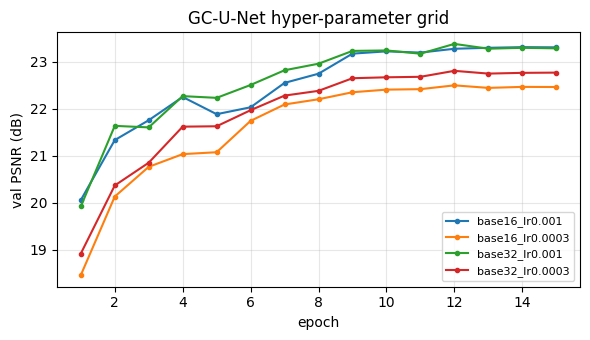

In [29]:
cnn_tune, tune_hist = [], []
for base in [16, 32]:
    for lr in [1e-3, 3e-4]:
        t0 = time.time()
        _, v, h = train_cnn(lambda: UNet(base, 0.0, global_context=True), CFG['TUNE_N'], epochs=CFG['TUNE_EPOCHS'],
                            lr=lr, wd=1e-4, aug=True, patience=99, tag=f'base{base}_lr{lr:g}', verbose=False)
        cnn_tune.append({'base_channels': base, 'lr': lr, 'params': n_params(UNet(base, global_context=True)),
                         'val_PSNR': v, 'time_s': time.time() - t0})
        tune_hist.append(h); print(f'  GC-U-Net base={base:<3} lr={lr:<7g} -> val PSNR {v:.3f}  ({time.time()-t0:.0f}s)')
cnn_tune = pd.DataFrame(cnn_tune).sort_values('val_PSNR', ascending=False)
cnn_tune.to_csv(OUT/'tuning_gc_unet.csv', index=False)
UNET_BASE, UNET_LR = int(cnn_tune.base_channels.iloc[0]), float(cnn_tune.lr.iloc[0])
print(f'\n-> best GC-U-Net config: base={UNET_BASE}, lr={UNET_LR:g}')

fig, ax = plt.subplots(figsize=(6, 3.5))
for h in tune_hist: ax.plot(h.epoch, h.val_PSNR, marker='o', ms=3, label=h.run.iloc[0])
ax.set_xlabel('epoch'); ax.set_ylabel('val PSNR (dB)'); ax.set_title('GC-U-Net hyper-parameter grid'); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG/'02_gc_unet_tuning.png', dpi=130); plt.show()

### M7b — Regularization ablation (GC-U-Net, best config)

| Run | Augmentation (h-flip, + random crop if `CROP` < 256) | Weight decay | Dropout (bottleneck) | Early stopping |
|---|---|---|---|---|
| **No regularization** | ✗ | 0 | 0 | ✗ (keeps best epoch, never stops early) |
| **Regularized** | ✓ | 1e-4 | 0.1 | ✓ (patience = `PATIENCE`) |

   [GC-U-Net no-reg] ep   1/120 | loss 0.1338 | val PSNR 19.99 | 10s
   [GC-U-Net no-reg] ep   5/120 | loss 0.0795 | val PSNR 22.68 | 53s
   [GC-U-Net no-reg] ep  10/120 | loss 0.0753 | val PSNR 23.38 | 105s
   [GC-U-Net no-reg] ep  15/120 | loss 0.0879 | val PSNR 22.40 | 157s
   [GC-U-Net no-reg] ep  20/120 | loss 0.0716 | val PSNR 23.60 | 208s
   [GC-U-Net no-reg] ep  25/120 | loss 0.0703 | val PSNR 23.66 | 258s
   [GC-U-Net no-reg] ep  30/120 | loss 0.3421 | val PSNR 23.52 | 309s
   [GC-U-Net no-reg] ep  35/120 | loss 0.1431 | val PSNR 20.70 | 359s
   [GC-U-Net no-reg] ep 36: diverged (0 non-finite batches, val PSNR 18.47) -> best weights restored, LR halved
   [GC-U-Net no-reg] ep  40/120 | loss 0.0674 | val PSNR 24.06 | 411s
   [GC-U-Net no-reg] ep  45/120 | loss 0.0671 | val PSNR 23.97 | 461s
   [GC-U-Net no-reg] ep  50/120 | loss 0.0663 | val PSNR 24.23 | 512s
   [GC-U-Net no-reg] ep  55/120 | loss 0.0659 | val PSNR 23.97 | 562s
   [GC-U-Net no-reg] ep  60/120 | loss 0.0660 | va

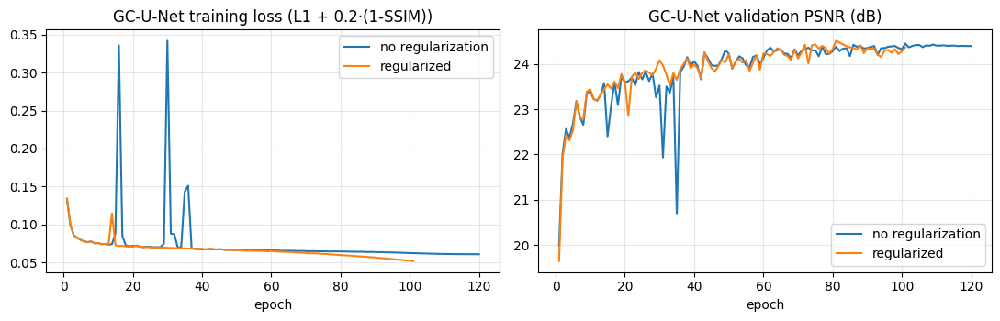

In [30]:
EP = CFG['EPOCHS']
gc_noreg, v_noreg, h_noreg = train_cnn(lambda: UNet(UNET_BASE, 0.0, global_context=True), CFG['CNN_TRAIN_N'], epochs=EP,
                                       lr=UNET_LR, wd=0.0, aug=False, patience=10 ** 9, tag='GC-U-Net no-reg')
gc_reg, v_reg, h_reg = train_cnn(lambda: UNet(UNET_BASE, 0.1, global_context=True), CFG['CNN_TRAIN_N'], epochs=EP,
                                 lr=UNET_LR, wd=1e-4, aug=True, patience=CFG['PATIENCE'], tag='GC-U-Net regularized')
ablation = pd.DataFrame([
    {'run': 'No regularization', 'best_val_PSNR': v_noreg, 'epochs_run': len(h_noreg), 'final_train_loss': h_noreg.train_loss.iloc[-1]},
    {'run': 'Regularized',       'best_val_PSNR': v_reg,   'epochs_run': len(h_reg),   'final_train_loss': h_reg.train_loss.iloc[-1]}])
print(); print(ablation.round(4).to_string(index=False))
ablation.to_csv(OUT/'ablation_regularization.csv', index=False)

GC_UNET = gc_reg if v_reg >= v_noreg else gc_noreg
GC_VARIANT = 'regularized' if v_reg >= v_noreg else 'no-reg'
v_gc = max(v_reg, v_noreg)
print(f'-> GC-U-Net kept for testing: {GC_VARIANT} (higher validation PSNR)')
torch.save(gc_reg.state_dict(), MODELS/'gc_unet_regularized.pt'); torch.save(gc_noreg.state_dict(), MODELS/'gc_unet_noreg.pt')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for h, lab in [(h_noreg, 'no regularization'), (h_reg, 'regularized')]:
    ax[0].plot(h.epoch, h.train_loss, label=lab); ax[1].plot(h.epoch, h.val_PSNR, label=lab)
ax[0].set_title('GC-U-Net training loss (L1 + 0.2·(1-SSIM))'); ax[1].set_title('GC-U-Net validation PSNR (dB)')
for a in ax: a.set_xlabel('epoch'); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG/'03_regularization_curves.png', dpi=130); plt.show()

### M7c — Global-context ablation: the same U-Net without the colour statistics

Same width, learning rate, regularization and budget as the GC-U-Net. The only difference is the global-context input.

In [31]:
unet, v_unet, h_unet = train_cnn(lambda: UNet(UNET_BASE, 0.1, global_context=False), CFG['CNN_TRAIN_N'], epochs=EP,
                                 lr=UNET_LR, wd=1e-4, aug=True, patience=CFG['PATIENCE'], tag='U-Net (no global context)')
torch.save(unet.state_dict(), MODELS/'unet_no_global_context.pt')
print(f'\nval PSNR: GC-U-Net {v_gc:.2f} dB vs U-Net {v_unet:.2f} dB -> global context adds {v_gc - v_unet:+.2f} dB')

   [U-Net (no global context)] ep   1/120 | loss 0.1513 | val PSNR 18.05 | 11s
   [U-Net (no global context)] ep   5/120 | loss 0.1444 | val PSNR 18.75 | 52s
   [U-Net (no global context)] ep  10/120 | loss 0.1278 | val PSNR 18.50 | 103s
   [U-Net (no global context)] ep  15/120 | loss 0.1295 | val PSNR 19.00 | 154s
   [U-Net (no global context)] ep  20/120 | loss 0.1239 | val PSNR 18.82 | 205s
   [U-Net (no global context)] ep  25/120 | loss 0.1233 | val PSNR 19.03 | 255s
   [U-Net (no global context)] ep  30/120 | loss 0.1213 | val PSNR 19.03 | 306s
   [U-Net (no global context)] ep  35/120 | loss 0.1200 | val PSNR 19.11 | 357s
   [U-Net (no global context)] ep  40/120 | loss 0.2420 | val PSNR 15.83 | 408s
   [U-Net (no global context)] ep  45/120 | loss 0.1193 | val PSNR 19.40 | 459s
   [U-Net (no global context)] ep  50/120 | loss 0.1164 | val PSNR 19.45 | 510s
   [U-Net (no global context)] ep  55/120 | loss 0.1137 | val PSNR 19.19 | 562s
   [U-Net (no global context)] ep  60/120 

### M7d — Plain CNN (same budget, same regularization)

   [Plain CNN] ep   1/120 | loss 0.1508 | val PSNR 18.27 | 8s
   [Plain CNN] ep   5/120 | loss 0.1330 | val PSNR 18.36 | 34s
   [Plain CNN] ep  10/120 | loss 0.1266 | val PSNR 19.19 | 67s
   [Plain CNN] ep  15/120 | loss 0.1231 | val PSNR 19.19 | 101s
   [Plain CNN] ep  20/120 | loss 0.1203 | val PSNR 19.04 | 133s
   [Plain CNN] ep  25/120 | loss 0.1199 | val PSNR 19.34 | 166s
   [Plain CNN] ep  30/120 | loss 0.1180 | val PSNR 19.28 | 199s
   [Plain CNN] ep  35/120 | loss 0.1207 | val PSNR 19.18 | 232s
   [Plain CNN] ep  40/120 | loss 0.1166 | val PSNR 19.07 | 265s
   [Plain CNN] ep  45/120 | loss 0.1160 | val PSNR 19.46 | 298s
   [Plain CNN] early stop at epoch 49 (best val PSNR 19.58)


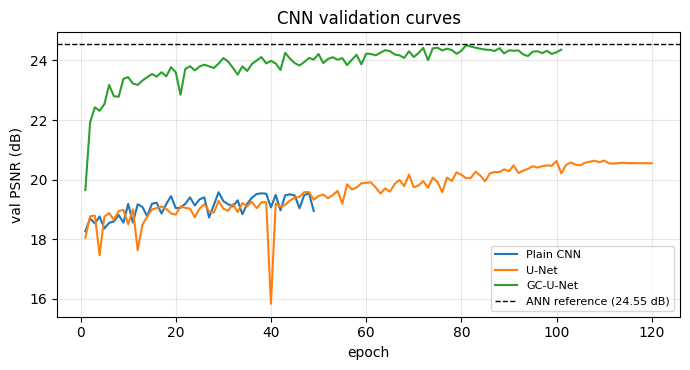

In [32]:
plain, v_plain, h_plain = train_cnn(lambda: PlainCNN(32, 8), CFG['CNN_TRAIN_N'], epochs=EP, lr=1e-3,
                                    wd=1e-4, aug=True, patience=CFG['PATIENCE'], tag='Plain CNN')
torch.save(plain.state_dict(), MODELS/'plain_cnn.pt')

fig, ax = plt.subplots(figsize=(7, 3.8))
for h, lab in [(h_plain, 'Plain CNN'), (h_unet, 'U-Net'), (h_reg if GC_VARIANT == 'regularized' else h_noreg, 'GC-U-Net')]:
    ax.plot(h.epoch, h.val_PSNR, label=lab)
ann_val_img = float(np.mean([psnr_u8(PREDICTORS['ANN (pixel MLP)'](X_va[i]), Y_va[i]) for i in VAL_IDX]))
ax.axhline(ann_val_img, ls='--', c='k', lw=1, label=f'ANN reference ({ann_val_img:.2f} dB)')
ax.set_xlabel('epoch'); ax.set_ylabel('val PSNR (dB)'); ax.set_title('CNN validation curves'); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG/'03b_cnn_val_curves.png', dpi=130); plt.show()

def cnn_fn(model):
    return lambda img: cnn_predict(model, img[None])[0]
for name, mdl in [('CNN-1 Plain CNN', plain), ('CNN-2 U-Net', unet), ('CNN-3 GC-U-Net', GC_UNET)]:
    PREDICTORS[name] = cnn_fn(mdl); FAMILY[name] = 'deep learning'; PARAMS[name] = n_params(mdl)
if DEVICE.type == 'cuda': torch.cuda.synchronize()

### M7e — Transformer: hybrid Vision Transformer (UIE-ViT)

**Why a transformer here.** A convolution only sees a small neighbourhood, so a CNN must stack many layers before one output pixel "sees" the whole image. In a transformer, **self-attention** lets every image patch look at every other patch in a single layer, giving it a global receptive field from the start.

That makes it the natural test of our main finding: the CNNs failed until we *gave* them whole-image colour statistics (GC-U-Net). **Can a transformer learn the global colour cast on its own, from raw pixels?** So this model gets **no** hand-made statistics.

**Self-attention in one line.** Each patch becomes a token and is projected into a query Q, a key K and a value V. Each token's output is a weighted average of all tokens' values, weighted by how well its query matches their keys:

$$\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d}}\right)V$$

With 4 heads, this runs 4 times in parallel on different 32-dimensional slices, so different heads can focus on different relationships (colour, brightness, structure).

**Architecture** (hybrid ViT: a convolutional stem for detail, a transformer for context):

| Part | Setting | Role |
|---|---|---|
| Conv stem | 2 × (3×3 conv, 32 ch, LeakyReLU) | keeps full-resolution edges and texture |
| Patch embedding | 8×8 conv, stride 8 → 128-dim tokens | 256×256 image → 32×32 = **1,024 tokens** |
| Positional embedding | learned, 32×32×128 (resized if the input size changes) | attention has no sense of position on its own |
| Transformer encoder | **6 blocks**, pre-norm, 4 heads, MLP 4× (512), GELU, dropout 0.1 | global self-attention over all 1,024 patches |
| Decoder | 1×1 conv + PixelShuffle ×8 → 32 ch at full resolution | turns tokens back into a full-size feature map |
| Fusion + output | concat with stem features → 3×3 convs → 3-ch residual (zero-init) | combines global context with local detail; starts as identity |

It has about **1.9 M parameters**, close to the U-Net (1.95 M), so the comparison is about *architecture*, not size. Training uses exactly the same data, loss (L1 + 0.2·(1−SSIM)), optimiser, schedule, regularization and early stopping as the CNNs. The only tuned setting is the learning rate (3e-4 vs 1e-4), because transformers are usually less stable than CNNs at high learning rates.

In [43]:
class UIETransformer(nn.Module):
    '''Hybrid Vision Transformer for enhancement: conv stem (local detail) + global self-attention over 8x8 patches.'''
    def __init__(self, dim=128, depth=6, heads=4, patch=8, stem=32, drop=0.1, img=IMG):
        super().__init__(); self.patch = patch
        self.stem = nn.Sequential(nn.Conv2d(3, stem, 3, padding=1), nn.LeakyReLU(0.2, inplace=True),
                                  nn.Conv2d(stem, stem, 3, padding=1), nn.LeakyReLU(0.2, inplace=True))
        self.embed = nn.Conv2d(stem, dim, patch, stride=patch)                 # (B, dim, H/8, W/8): one token per 8x8 patch
        self.pos = nn.Parameter(torch.zeros(1, dim, img // patch, img // patch))
        nn.init.trunc_normal_(self.pos, std=0.02)
        block = nn.TransformerEncoderLayer(d_model=dim, nhead=heads, dim_feedforward=4 * dim, dropout=drop,
                                           activation='gelu', batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(block, num_layers=depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(dim)
        self.up = nn.Sequential(nn.Conv2d(dim, stem * patch * patch, 1), nn.PixelShuffle(patch))  # tokens -> full resolution
        self.fuse = nn.Sequential(nn.Conv2d(2 * stem, stem, 3, padding=1), nn.LeakyReLU(0.2, inplace=True),
                                  nn.Conv2d(stem, 3, 3, padding=1))
        nn.init.zeros_(self.fuse[-1].weight); nn.init.zeros_(self.fuse[-1].bias)   # starts as the identity mapping

    def forward(self, x, g=None):                      # g (colour statistics) is deliberately ignored
        B = x.shape[0]
        s = self.stem(x)                               # (B, 32, H, W)
        t = self.embed(s); h, w = t.shape[2], t.shape[3]
        pos = self.pos if (self.pos.shape[2], self.pos.shape[3]) == (h, w) else \
              F.interpolate(self.pos, size=(h, w), mode='bicubic', align_corners=False)
        t = (t + pos).flatten(2).transpose(1, 2)       # (B, N tokens, dim)
        t = self.norm(self.encoder(t))                 # global self-attention, every token sees every token
        t = t.transpose(1, 2).reshape(B, -1, h, w)     # back to a (B, dim, h, w) grid
        return x + self.fuse(torch.cat([self.up(t), s], 1))

_tf = UIETransformer()
with torch.no_grad(): _out = _tf(torch.zeros(1, 3, IMG, IMG))
print(f'Transformer params: {n_params(_tf):,} (U-Net: {n_params(UNet(32)):,}) | tokens per image: {(IMG // 8) ** 2} '
      f'| output shape {tuple(_out.shape)}')
del _tf, _out

Transformer params: 1,876,899 (U-Net: 1,946,947) | tokens per image: 1024 | output shape (1, 3, 256, 256)


#### M7e (training) — learning-rate tuning, then the final run

Two short runs pick the learning rate on validation PSNR. The final run uses the same budget, regularization and early stopping as the other CNNs.

  Transformer lr=0.0003  -> val PSNR 21.393  (86s)
  Transformer lr=0.0001  -> val PSNR 20.749  (85s)
-> chosen learning rate 0.0003

   [Transformer] ep   1/120 | loss 0.1489 | val PSNR 18.73 | 9s
   [Transformer] ep   5/120 | loss 0.1101 | val PSNR 20.91 | 47s
   [Transformer] ep  10/120 | loss 0.0918 | val PSNR 22.24 | 94s
   [Transformer] ep  15/120 | loss 0.0853 | val PSNR 22.26 | 141s
   [Transformer] ep  20/120 | loss 0.0803 | val PSNR 22.22 | 188s
   [Transformer] ep  25/120 | loss 0.0783 | val PSNR 22.06 | 235s
   [Transformer] ep  30/120 | loss 0.0749 | val PSNR 22.84 | 282s
   [Transformer] ep  35/120 | loss 0.0726 | val PSNR 23.14 | 329s
   [Transformer] ep  40/120 | loss 0.0698 | val PSNR 23.24 | 376s
   [Transformer] ep  45/120 | loss 0.0692 | val PSNR 23.24 | 423s
   [Transformer] ep  50/120 | loss 0.0659 | val PSNR 23.14 | 470s
   [Transformer] ep  55/120 | loss 0.0631 | val PSNR 23.68 | 518s
   [Transformer] ep  60/120 | loss 0.0597 | val PSNR 23.31 | 565s
   [Transfor

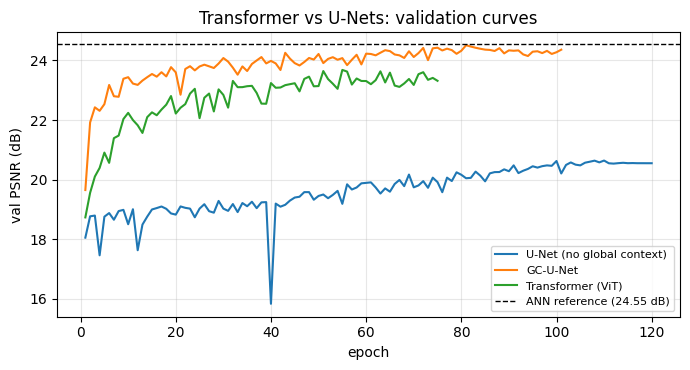

In [44]:
tf_tune = []
for lr in [3e-4, 1e-4]:
    t0 = time.time()
    _, v, _ = train_cnn(lambda: UIETransformer(drop=0.1), CFG['TUNE_N'], epochs=CFG['TUNE_EPOCHS'], lr=lr, wd=1e-4,
                        aug=True, patience=99, tag=f'tf_lr{lr:g}', verbose=False)
    tf_tune.append({'lr': lr, 'val_PSNR': v, 'time_s': time.time() - t0})
    print(f'  Transformer lr={lr:<7g} -> val PSNR {v:.3f}  ({time.time()-t0:.0f}s)')
tf_tune = pd.DataFrame(tf_tune).sort_values('val_PSNR', ascending=False)
tf_tune.to_csv(OUT/'tuning_transformer.csv', index=False)
TF_LR = float(tf_tune.lr.iloc[0]); print(f'-> chosen learning rate {TF_LR:g}\n')

tf, v_tf, h_tf = train_cnn(lambda: UIETransformer(drop=0.1), CFG['CNN_TRAIN_N'], epochs=EP, lr=TF_LR,
                           wd=1e-4, aug=True, patience=CFG['PATIENCE'], tag='Transformer')
torch.save(tf.state_dict(), MODELS/'transformer_vit.pt')
print(f'\nval PSNR: Transformer {v_tf:.2f} dB | U-Net (no global context) {v_unet:.2f} dB | GC-U-Net {v_gc:.2f} dB')

fig, ax = plt.subplots(figsize=(7, 3.8))
for h, lab in [(h_unet, 'U-Net (no global context)'), (h_reg if GC_VARIANT == 'regularized' else h_noreg, 'GC-U-Net'),
               (h_tf, 'Transformer (ViT)')]:
    ax.plot(h.epoch, h.val_PSNR, label=lab)
ax.axhline(ann_val_img, ls='--', c='k', lw=1, label=f'ANN reference ({ann_val_img:.2f} dB)')
ax.set_xlabel('epoch'); ax.set_ylabel('val PSNR (dB)'); ax.set_title('Transformer vs U-Nets: validation curves')
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG/'03c_transformer_curves.png', dpi=130); plt.show()

PREDICTORS['Transformer (ViT)'] = cnn_fn(tf); FAMILY['Transformer (ViT)'] = 'deep learning'; PARAMS['Transformer (ViT)'] = n_params(tf)
if DEVICE.type == 'cuda': torch.cuda.synchronize()

---
## Step M8 — Test-set evaluation (T89, full-reference + no-reference)

Every method is scored on the same 89 held-out test pairs at 256×256. `ms` is wall-clock time per image, including feature extraction for the pixel models (CNN timings are on the current device).

In [45]:
test_ids = split['test']['meta'].clean_id.tolist()
per_img, PRED_TE = [], {}
for name, fn in PREDICTORS.items():
    t0 = time.time(); df, P = evaluate(name, fn, X_te, Y_te, test_ids)
    per_img.append(df); PRED_TE[name] = P
    print(f'{name:<22} PSNR {df.PSNR.mean():6.2f} | SSIM {df.SSIM.mean():.3f} | UIQM {df.UIQM.mean():.3f} | '
          f'UCIQE {df.UCIQE.mean():.3f} | {df.ms.median():7.1f} ms/img  ({time.time()-t0:.0f}s)')
per_img = pd.concat(per_img, ignore_index=True)
per_img.to_csv(OUT/'test_per_image.csv', index=False)

ref_nr = {'UIQM': np.mean([uiqm(y) for y in Y_te]), 'UCIQE': np.mean([uciqe(y) for y in Y_te])}
order = list(PREDICTORS)
g = per_img.groupby('method')
results = pd.DataFrame({
    'family': [FAMILY[m] for m in order],
    'PSNR': g.PSNR.mean()[order].values, 'PSNR_std': g.PSNR.std()[order].values,
    'SSIM': g.SSIM.mean()[order].values, 'SSIM_std': g.SSIM.std()[order].values,
    'UIQM': g.UIQM.mean()[order].values, 'UCIQE': g.UCIQE.mean()[order].values,
    'ms_per_img': g.ms.median()[order].values, 'params': [PARAMS[m] for m in order]}, index=order)
results.index.name = 'method'
results.to_csv(OUT/'test_results.csv')
print(f'\nReference images themselves: UIQM {ref_nr["UIQM"]:.3f} | UCIQE {ref_nr["UCIQE"]:.3f}')
display_cols = ['family', 'PSNR', 'SSIM', 'UIQM', 'UCIQE', 'ms_per_img', 'params']
results[display_cols].round(3)

Raw input              PSNR  17.22 | SSIM 0.752 | UIQM 2.688 | UCIQE 0.338 |     0.0 ms/img  (3s)
Gray-World             PSNR  17.19 | SSIM 0.761 | UIQM 2.759 | UCIQE 0.306 |     1.9 ms/img  (3s)
Gray-World + CLAHE     PSNR  17.70 | SSIM 0.827 | UIQM 3.081 | UCIQE 0.339 |     3.6 ms/img  (3s)
ML-1 Ridge (poly-2)    PSNR  23.68 | SSIM 0.915 | UIQM 3.036 | UCIQE 0.395 |   190.5 ms/img  (21s)
ML-2 Random Forest     PSNR  22.70 | SSIM 0.880 | UIQM 3.233 | UCIQE 0.362 |   215.5 ms/img  (22s)
ANN (pixel MLP)        PSNR  24.73 | SSIM 0.921 | UIQM 3.103 | UCIQE 0.395 |    17.9 ms/img  (5s)
CNN-1 Plain CNN        PSNR  19.40 | SSIM 0.864 | UIQM 3.166 | UCIQE 0.340 |    12.3 ms/img  (4s)
CNN-2 U-Net            PSNR  20.81 | SSIM 0.889 | UIQM 3.212 | UCIQE 0.371 |    15.6 ms/img  (4s)
CNN-3 GC-U-Net         PSNR  24.47 | SSIM 0.920 | UIQM 3.036 | UCIQE 0.401 |    16.7 ms/img  (5s)
Transformer (ViT)      PSNR  23.44 | SSIM 0.909 | UIQM 3.184 | UCIQE 0.392 |    17.5 ms/img  (5s)

Reference images 

,family,PSNR,SSIM,UIQM,UCIQE,ms_per_img,params
method,,,,,,,
Raw input,reference,17.219,0.752,2.688,0.338,0.002,0
Gray-World,classical,17.191,0.761,2.759,0.306,1.898,0
Gray-World + CLAHE,classical,17.700,0.827,3.081,0.339,3.592,0
ML-1 Ridge (poly-2),ML baseline,23.681,0.915,3.036,0.395,190.496,759
ML-2 Random Forest,ML baseline,22.696,0.880,3.233,0.362,215.539,7212104
ANN (pixel MLP),deep learning,24.730,0.921,3.103,0.395,17.882,11267
CNN-1 Plain CNN,deep learning,19.399,0.864,3.166,0.340,12.300,57251
CNN-2 U-Net,deep learning,20.806,0.889,3.212,0.371,15.597,1946947
CNN-3 GC-U-Net,deep learning,24.474,0.920,3.036,0.401,16.687,2023887


---
## Step M9 — Comparative analysis

- Bar chart with ±1 std error bars
- **Paired Wilcoxon signed-rank test** (same 89 images under every method), best deep model vs best ML baseline
- Per-image **win-rate**
- Visual comparison and worst-case (failure) images

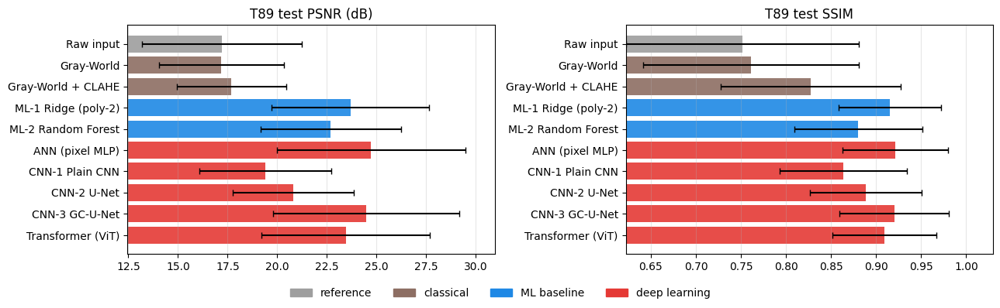

Best ML baseline: ML-1 Ridge (poly-2) | best deep model: ANN (pixel MLP)

                A                   B  mean_dPSNR (A-B)  A wins (%)  Wilcoxon p
  ANN (pixel MLP) ML-1 Ridge (poly-2)            1.0493     65.1685      0.0001
  ANN (pixel MLP)  Gray-World + CLAHE            7.0296     87.6404      0.0000
  ANN (pixel MLP)           Raw input            7.5109     92.1348      0.0000
   CNN-3 GC-U-Net     ANN (pixel MLP)           -0.2558     46.0674      0.1306
   CNN-3 GC-U-Net         CNN-2 U-Net            3.6684     83.1461      0.0000
      CNN-2 U-Net     CNN-1 Plain CNN            1.4066     80.8989      0.0000
Transformer (ViT)         CNN-2 U-Net            2.6374     76.4045      0.0000
   CNN-3 GC-U-Net   Transformer (ViT)            1.0310     60.6742      0.0122
Transformer (ViT)     ANN (pixel MLP)           -1.2868     39.3258      0.0007


In [46]:
fam_col = {'reference': '#9e9e9e', 'classical': '#8d6e63', 'ML baseline': '#1e88e5', 'deep learning': '#e53935'}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, met in zip(ax, ['PSNR', 'SSIM']):
    a.barh(results.index[::-1], results[met][::-1], xerr=results[f'{met}_std'][::-1],
           color=[fam_col[f] for f in results.family[::-1]], alpha=.9, capsize=3)
    a.set_title(f'T89 test {met}' + (' (dB)' if met == 'PSNR' else '')); a.grid(axis='x', alpha=.3)
    lo = results[met].min() - results[f'{met}_std'].max(); a.set_xlim(max(0, lo), None)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in fam_col.values()]
fig.legend(handles, fam_col.keys(), loc='lower center', ncol=4, frameon=False)
plt.tight_layout(rect=(0, .07, 1, 1)); plt.savefig(FIG/'04_test_metrics.png', dpi=130, bbox_inches='tight'); plt.show()

ml_names = [m for m in order if FAMILY[m] == 'ML baseline']
dl_names = [m for m in order if FAMILY[m] == 'deep learning']
best_ml = results.loc[ml_names].PSNR.idxmax(); best_dl = results.loc[dl_names].PSNR.idxmax()
piv = per_img.pivot(index='id', columns='method', values='PSNR')
sig = []
for a_, b_ in [(best_dl, best_ml), (best_dl, 'Gray-World + CLAHE'), (best_dl, 'Raw input'),
               ('CNN-3 GC-U-Net', 'ANN (pixel MLP)'), ('CNN-3 GC-U-Net', 'CNN-2 U-Net'),
               ('CNN-2 U-Net', 'CNN-1 Plain CNN'), ('Transformer (ViT)', 'CNN-2 U-Net'),
               ('CNN-3 GC-U-Net', 'Transformer (ViT)'), ('Transformer (ViT)', 'ANN (pixel MLP)')]:
    if a_ == b_: continue
    d = piv[a_] - piv[b_]
    try: p = stats.wilcoxon(piv[a_], piv[b_]).pvalue
    except ValueError: p = float('nan')
    sig.append({'A': a_, 'B': b_, 'mean_dPSNR (A-B)': d.mean(), 'A wins (%)': 100 * (d > 0).mean(), 'Wilcoxon p': p})
sig = pd.DataFrame(sig).drop_duplicates(['A', 'B']).reset_index(drop=True)
sig.to_csv(OUT/'significance_tests.csv', index=False)
print(f'Best ML baseline: {best_ml} | best deep model: {best_dl}\n')
print(sig.round(4).to_string(index=False))

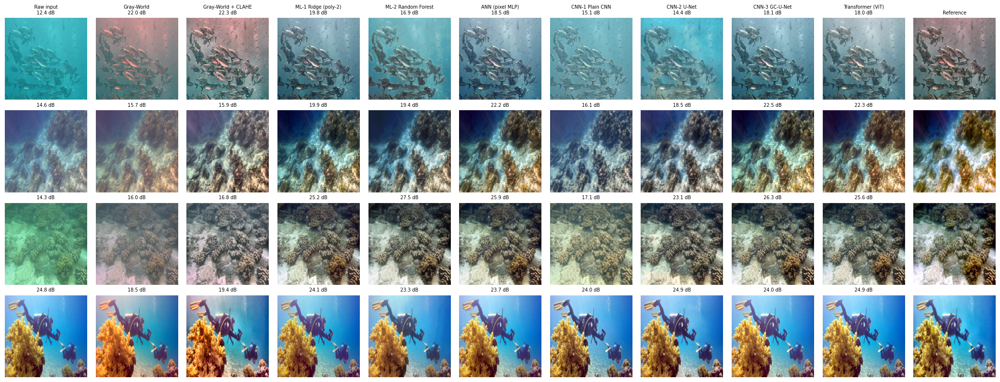

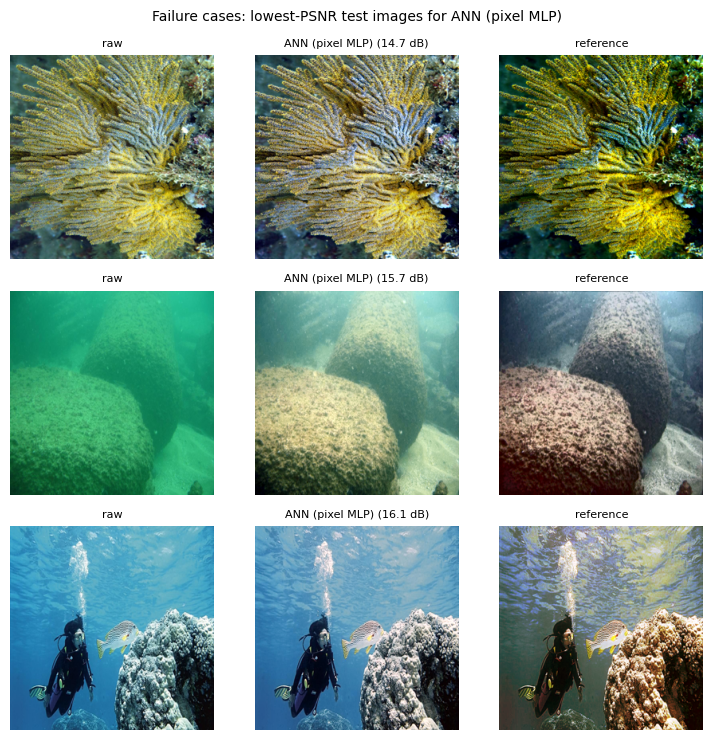

In [47]:
show = [m for m in order]
vis = np.random.default_rng(SEED).choice(len(X_te), size=min(4, len(X_te)), replace=False)
ncol = len(show) + 1
fig, ax = plt.subplots(len(vis), ncol, figsize=(1.9 * ncol, 2.0 * len(vis)))
ax = np.atleast_2d(ax)
for r_, i in enumerate(vis):
    for c_, m in enumerate(show):
        ax[r_, c_].imshow(PRED_TE[m][i]); ax[r_, c_].axis('off')
        ax[r_, c_].set_title(f'{m}\n{psnr_u8(PRED_TE[m][i], Y_te[i]):.1f} dB' if r_ == 0 else
                             f'{psnr_u8(PRED_TE[m][i], Y_te[i]):.1f} dB', fontsize=7)
    ax[r_, -1].imshow(Y_te[i]); ax[r_, -1].axis('off')
    if r_ == 0: ax[r_, -1].set_title('Reference', fontsize=7)
plt.tight_layout(); plt.savefig(FIG/'05_visual_comparison_test.png', dpi=140, bbox_inches='tight'); plt.show()

worst = per_img[per_img.method == best_dl].nsmallest(3, 'PSNR')
idx_of = {c: k for k, c in enumerate(test_ids)}
fig, ax = plt.subplots(len(worst), 3, figsize=(7.5, 2.5 * len(worst))); ax = np.atleast_2d(ax)
for r_, (_, row) in enumerate(worst.iterrows()):
    i = idx_of[row.id]
    for c_, (im, t) in enumerate([(X_te[i], 'raw'), (PRED_TE[best_dl][i], f'{best_dl} ({row.PSNR:.1f} dB)'), (Y_te[i], 'reference')]):
        ax[r_, c_].imshow(im); ax[r_, c_].set_title(t, fontsize=8); ax[r_, c_].axis('off')
plt.suptitle(f'Failure cases: lowest-PSNR test images for {best_dl}', fontsize=10)
plt.tight_layout(); plt.savefig(FIG/'06_failure_cases.png', dpi=130, bbox_inches='tight'); plt.show()

---
## Step M10 — C60 challenge set (no references)

The 60 images for which no acceptable reference exists. Only **no-reference** metrics apply. A useful sanity check: does a model that scores well on T89 still help on the hardest scenes?

                      UIQM  UCIQE
method                           
Raw input            2.086  0.331
Gray-World           2.112  0.269
Gray-World + CLAHE   2.664  0.299
ML-1 Ridge (poly-2)  2.547  0.372
ML-2 Random Forest   2.669  0.335
ANN (pixel MLP)      2.594  0.368
CNN-1 Plain CNN      2.643  0.323
CNN-2 U-Net          2.831  0.353
CNN-3 GC-U-Net       2.571  0.383
Transformer (ViT)    2.934  0.362


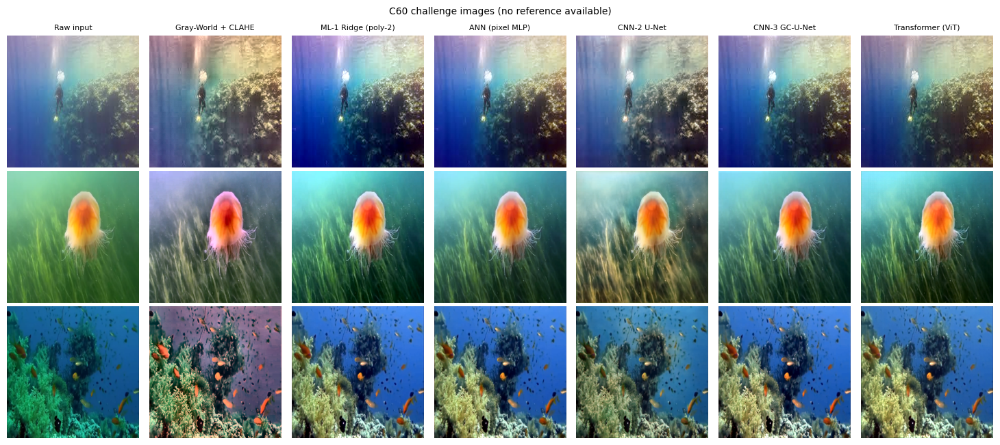

In [48]:
if len(X_ch):
    chal_rows, PRED_CH = [], {}
    for name, fn in PREDICTORS.items():
        df, P = evaluate(name, fn, X_ch, None, chal.clean_id.tolist()); chal_rows.append(df); PRED_CH[name] = P
    chal_df = pd.concat(chal_rows, ignore_index=True); chal_df.to_csv(OUT/'challenge_per_image.csv', index=False)
    chal_res = chal_df.groupby('method')[['UIQM', 'UCIQE']].mean().loc[order]
    chal_res.to_csv(OUT/'challenge_results.csv'); print(chal_res.round(3).to_string())

    pick_c = np.random.default_rng(SEED).choice(len(X_ch), size=min(3, len(X_ch)), replace=False)
    cols = ['Raw input', 'Gray-World + CLAHE', best_ml, 'ANN (pixel MLP)', 'CNN-2 U-Net', 'CNN-3 GC-U-Net', 'Transformer (ViT)']
    fig, ax = plt.subplots(len(pick_c), len(cols), figsize=(2.1 * len(cols), 2.2 * len(pick_c))); ax = np.atleast_2d(ax)
    for r_, i in enumerate(pick_c):
        for c_, m in enumerate(cols):
            ax[r_, c_].imshow(PRED_CH[m][i]); ax[r_, c_].axis('off')
            if r_ == 0: ax[r_, c_].set_title(m, fontsize=8)
    plt.suptitle('C60 challenge images (no reference available)', fontsize=10)
    plt.tight_layout(); plt.savefig(FIG/'07_challenge_c60.png', dpi=140, bbox_inches='tight'); plt.show()
else:
    chal_res = None; print('No challenge images found - skipped.')

---
## Step M11 — Mid-term summary (auto-written)

Writes `midterm_summary.md` with the configuration, all result tables and **key findings computed from this run**, ready to paste into the mid-term presentation and report.

In [49]:
def md_table(df, floatfmt=3):
    df = df.reset_index() if df.index.name else df
    fmt = lambda v: (f'{v:,.{floatfmt}f}' if isinstance(v, (float, np.floating)) and not (isinstance(v, float) and math.isnan(v))
                     else (f'{v:,}' if isinstance(v, (int, np.integer)) else str(v)))
    lines = ['| ' + ' | '.join(map(str, df.columns)) + ' |', '|' + '---|' * len(df.columns)]
    lines += ['| ' + ' | '.join(fmt(v) for v in row) + ' |' for row in df.itertuples(index=False)]
    return '\n'.join(lines)

raw_psnr = results.loc['Raw input', 'PSNR']
best_all = results.drop('Raw input').PSNR.idxmax()
f = []
f.append(f'**{best_all}** is the best method on T89: {results.loc[best_all, "PSNR"]:.2f} dB PSNR / '
         f'{results.loc[best_all, "SSIM"]:.3f} SSIM, +{results.loc[best_all, "PSNR"] - raw_psnr:.2f} dB over the raw input.')
s0 = sig[(sig.A == best_dl) & (sig.B == best_ml)]
if len(s0):
    s0 = s0.iloc[0]
    f.append(f'Best deep model ({best_dl}) vs best ML baseline ({best_ml}): {s0["mean_dPSNR (A-B)"]:+.2f} dB mean, '
             f'wins on {s0["A wins (%)"]:.0f}% of test images, Wilcoxon p = {s0["Wilcoxon p"]:.2g}.')
f.append(f'ML baselines: Ridge {results.loc["ML-1 Ridge (poly-2)", "PSNR"]:.2f} dB, Random Forest '
         f'{results.loc["ML-2 Random Forest", "PSNR"]:.2f} dB; classical Gray-World + CLAHE {results.loc["Gray-World + CLAHE", "PSNR"]:.2f} dB.')
f.append(f'ANN on hand-crafted pixel features: {results.loc["ANN (pixel MLP)", "PSNR"]:.2f} dB, '
         f'{results.loc["ANN (pixel MLP)", "PSNR"] - results.loc[best_ml, "PSNR"]:+.2f} dB vs {best_ml} on the same features.')
gcu, un, pc = (results.loc[k, 'PSNR'] for k in ['CNN-3 GC-U-Net', 'CNN-2 U-Net', 'CNN-1 Plain CNN'])
f.append(f'Global context: GC-U-Net {gcu:.2f} dB vs the same U-Net without colour statistics {un:.2f} dB '
         f'({gcu - un:+.2f} dB on test; {v_gc - v_unet:+.2f} dB on validation).')
f.append(f'GC-U-Net vs ANN (pixel MLP): {gcu - results.loc["ANN (pixel MLP)", "PSNR"]:+.2f} dB. '
         f'U-Net vs plain CNN: {un - pc:+.2f} dB (larger receptive field vs ~17-px local field).')
tfp = results.loc['Transformer (ViT)', 'PSNR']
f.append(f'Transformer (global self-attention, no colour statistics): {tfp:.2f} dB on test, {tfp - un:+.2f} dB vs the U-Net '
         f'and {tfp - gcu:+.2f} dB vs the GC-U-Net (val {v_tf:.2f} dB, learning rate {TF_LR:g}).')
f.append(f'Regularization ablation on GC-U-Net (val PSNR): regularized {v_reg:.2f} dB vs none {v_noreg:.2f} dB '
         f'({v_reg - v_noreg:+.2f} dB); regularized run stopped after {len(h_reg)} of {EP} epochs.')
f.append(f'Tuned settings: Ridge alpha={best_alpha:g}; RF max_depth={best_depth}; ANN hidden={ANN_HIDDEN}, dropout={ANN_DROP}; '
         f'GC-U-Net base={UNET_BASE}, lr={UNET_LR:g}.')
if chal_res is not None:
    f.append(f'C60 (no reference): UIQM raw {chal_res.loc["Raw input", "UIQM"]:.3f} -> {best_dl} {chal_res.loc[best_dl, "UIQM"]:.3f}; '
             f'UCIQE raw {chal_res.loc["Raw input", "UCIQE"]:.3f} -> {best_dl} {chal_res.loc[best_dl, "UCIQE"]:.3f}.')

L = []; A = L.append
A('# UIEB - Mid-Term Results (Weeks 1-8)'); A('')
A(f'- **Run:** {RUN_STARTED} | mode `{RUN_MODE}` | device `{DEVICE}` | seed {SEED}')
A(f'- **Data:** {DATA_SOURCE}; train {len(X_tr)} / val {len(X_va)} / test {len(X_te)} / C60 {len(X_ch)}, all at {IMG}x{IMG}')
A(f'- **CNN training budget:** {CFG["CNN_TRAIN_N"] or len(X_tr)} training images, {CFG["CROP"]}px random crops, up to {EP} epochs, '
  f'batch {CFG["BATCH"]}. ML/ANN models use all {len(X_tr)} training images ({CFG["PIX_PER_IMG"]} pixels each).')
if RUN_MODE == 'sample':
    A('- *CNNs were trained on a sample for compute reasons; their numbers are a lower bound on what full training gives.*')
A(''); A('## Key findings'); A('')
for x in f: A(f'- {x}')
A(''); A('## T89 test results'); A('')
A(md_table(results[display_cols]))
A(''); A(f'Reference images themselves: UIQM {ref_nr["UIQM"]:.3f}, UCIQE {ref_nr["UCIQE"]:.3f}.')
A(''); A('## Statistical tests (paired, per-image PSNR)'); A(''); A(md_table(sig, 4))
A(''); A('## Hyper-parameter tuning'); A('')
A('**Ridge** (val pixel PSNR)'); A(''); A(md_table(ridge_tune)); A('')
A('**Random Forest** (val pixel PSNR, 20-tree probe)'); A(''); A(md_table(rf_tune)); A('')
A('**ANN**'); A(''); A(md_table(ann_tune)); A('')
A('**GC-U-Net**'); A(''); A(md_table(cnn_tune)); A('')
A('**Transformer**'); A(''); A(md_table(tf_tune)); A('')
A('## Regularization ablation (GC-U-Net)'); A(''); A(md_table(ablation, 4)); A('')
A('## Global-context ablation (validation PSNR)'); A('')
A(md_table(pd.DataFrame([{'model': 'GC-U-Net', 'val_PSNR': v_gc}, {'model': 'U-Net (no global context)', 'val_PSNR': v_unet},
                         {'model': 'Plain CNN', 'val_PSNR': v_plain},
                         {'model': 'Transformer (ViT)', 'val_PSNR': v_tf}]))); A('')
if chal_res is not None:
    A('## C60 challenge set (no-reference)'); A(''); A(md_table(chal_res)); A('')
A('## Figures'); A('')
for p in sorted(FIG.glob('*.png')): A(f'- `figures/{p.name}`')
A(''); A('## Gantt status at mid-term'); A('')
for item in ['Problem statement, dataset selection, ETL & EDA', 'Two ML baseline models (Ridge, Random Forest)',
             'Deep learning architectures implemented (ANN, plain CNN, U-Net, GC-U-Net, Transformer)', 'Hyper-parameter tuning',
             'Model improvement: global-context conditioning (GC-U-Net) + ablation',
             'Regularization (augmentation, weight decay, dropout, early stopping) + ablation',
             'Evaluation (PSNR, SSIM, UIQM, UCIQE, significance tests, C60)']:
    A(f'- [x] {item}')
A(''); A('## Next steps (Phase III)'); A('')
for item in ['Re-train CNNs with `RUN_MODE = "full"` and report those numbers as final',
             'Train on LSUI and test on UIEB-T90; run the leakage check from Part 1 (Step 6) first',
             'Hybrid: let the GC-U-Net or Transformer refine the ANN output; try a perceptual (VGG) loss',
             'Ablation of loss terms (L1 vs L1+SSIM) and of the residual/skip design',
             'Downstream maritime check, e.g. detection on enhanced vs raw images']:
    A(f'- [ ] {item}')
summary_md = '\n'.join(L)
(OUT/'midterm_summary.md').write_text(summary_md)
print('Wrote', OUT/'midterm_summary.md'); print()
for x in f: print(' -', x)

Wrote /kaggle/working/midterm/midterm_summary.md

 - **ANN (pixel MLP)** is the best method on T89: 24.73 dB PSNR / 0.921 SSIM, +7.51 dB over the raw input.
 - Best deep model (ANN (pixel MLP)) vs best ML baseline (ML-1 Ridge (poly-2)): +1.05 dB mean, wins on 65% of test images, Wilcoxon p = 8.4e-05.
 - ML baselines: Ridge 23.68 dB, Random Forest 22.70 dB; classical Gray-World + CLAHE 17.70 dB.
 - ANN on hand-crafted pixel features: 24.73 dB, +1.05 dB vs ML-1 Ridge (poly-2) on the same features.
 - Global context: GC-U-Net 24.47 dB vs the same U-Net without colour statistics 20.81 dB (+3.67 dB on test; +3.87 dB on validation).
 - GC-U-Net vs ANN (pixel MLP): -0.26 dB. U-Net vs plain CNN: +1.41 dB (larger receptive field vs ~17-px local field).
 - Transformer (global self-attention, no colour statistics): 23.44 dB on test, +2.64 dB vs the U-Net and -1.03 dB vs the GC-U-Net (val 23.68 dB, learning rate 0.0003).
 - Regularization ablation on GC-U-Net (val PSNR): regularized 24.51 dB vs no

In [50]:
from IPython.display import Markdown, display
display(Markdown(summary_md))

# UIEB - Mid-Term Results (Weeks 1-8)

- **Run:** 2026-11-22 05:14:33 | mode `full` | device `cuda` | seed 42
- **Data:** cleaned dataset at /kaggle/working/uieb_clean; train 712 / val 79 / test 89 / C60 60, all at 256x256
- **CNN training budget:** 712 training images, 256px random crops, up to 120 epochs, batch 8. ML/ANN models use all 712 training images (2000 pixels each).

## Key findings

- **ANN (pixel MLP)** is the best method on T89: 24.73 dB PSNR / 0.921 SSIM, +7.51 dB over the raw input.
- Best deep model (ANN (pixel MLP)) vs best ML baseline (ML-1 Ridge (poly-2)): +1.05 dB mean, wins on 65% of test images, Wilcoxon p = 8.4e-05.
- ML baselines: Ridge 23.68 dB, Random Forest 22.70 dB; classical Gray-World + CLAHE 17.70 dB.
- ANN on hand-crafted pixel features: 24.73 dB, +1.05 dB vs ML-1 Ridge (poly-2) on the same features.
- Global context: GC-U-Net 24.47 dB vs the same U-Net without colour statistics 20.81 dB (+3.67 dB on test; +3.87 dB on validation).
- GC-U-Net vs ANN (pixel MLP): -0.26 dB. U-Net vs plain CNN: +1.41 dB (larger receptive field vs ~17-px local field).
- Transformer (global self-attention, no colour statistics): 23.44 dB on test, +2.64 dB vs the U-Net and -1.03 dB vs the GC-U-Net (val 23.68 dB, learning rate 0.0003).
- Regularization ablation on GC-U-Net (val PSNR): regularized 24.51 dB vs none 24.45 dB (+0.06 dB); regularized run stopped after 101 of 120 epochs.
- Tuned settings: Ridge alpha=100; RF max_depth=20; ANN hidden=(128, 64), dropout=0.1; GC-U-Net base=32, lr=0.001.
- C60 (no reference): UIQM raw 2.086 -> ANN (pixel MLP) 2.594; UCIQE raw 0.331 -> ANN (pixel MLP) 0.368.

## T89 test results

| method | family | PSNR | SSIM | UIQM | UCIQE | ms_per_img | params |
|---|---|---|---|---|---|---|---|
| Raw input | reference | 17.219 | 0.752 | 2.688 | 0.338 | 0.002 | 0 |
| Gray-World | classical | 17.191 | 0.761 | 2.759 | 0.306 | 1.898 | 0 |
| Gray-World + CLAHE | classical | 17.700 | 0.827 | 3.081 | 0.339 | 3.592 | 0 |
| ML-1 Ridge (poly-2) | ML baseline | 23.681 | 0.915 | 3.036 | 0.395 | 190.496 | 759 |
| ML-2 Random Forest | ML baseline | 22.696 | 0.880 | 3.233 | 0.362 | 215.539 | 7,212,104 |
| ANN (pixel MLP) | deep learning | 24.730 | 0.921 | 3.103 | 0.395 | 17.882 | 11,267 |
| CNN-1 Plain CNN | deep learning | 19.399 | 0.864 | 3.166 | 0.340 | 12.300 | 57,251 |
| CNN-2 U-Net | deep learning | 20.806 | 0.889 | 3.212 | 0.371 | 15.597 | 1,946,947 |
| CNN-3 GC-U-Net | deep learning | 24.474 | 0.920 | 3.036 | 0.401 | 16.687 | 2,023,887 |
| Transformer (ViT) | deep learning | 23.443 | 0.909 | 3.184 | 0.392 | 17.546 | 1,876,899 |

Reference images themselves: UIQM 3.043, UCIQE 0.408.

## Statistical tests (paired, per-image PSNR)

| A | B | mean_dPSNR (A-B) | A wins (%) | Wilcoxon p |
|---|---|---|---|---|
| ANN (pixel MLP) | ML-1 Ridge (poly-2) | 1.0493 | 65.1685 | 0.0001 |
| ANN (pixel MLP) | Gray-World + CLAHE | 7.0296 | 87.6404 | 0.0000 |
| ANN (pixel MLP) | Raw input | 7.5109 | 92.1348 | 0.0000 |
| CNN-3 GC-U-Net | ANN (pixel MLP) | -0.2558 | 46.0674 | 0.1306 |
| CNN-3 GC-U-Net | CNN-2 U-Net | 3.6684 | 83.1461 | 0.0000 |
| CNN-2 U-Net | CNN-1 Plain CNN | 1.4066 | 80.8989 | 0.0000 |
| Transformer (ViT) | CNN-2 U-Net | 2.6374 | 76.4045 | 0.0000 |
| CNN-3 GC-U-Net | Transformer (ViT) | 1.0310 | 60.6742 | 0.0122 |
| Transformer (ViT) | ANN (pixel MLP) | -1.2868 | 39.3258 | 0.0007 |

## Hyper-parameter tuning

**Ridge** (val pixel PSNR)

| alpha | val_pixel_PSNR | fit_s |
|---|---|---|
| 0.010 | 21.616 | 0.770 |
| 1.000 | 21.616 | 0.765 |
| 100.000 | 21.618 | 0.757 |
| 1,000.000 | 21.616 | 0.753 |

**Random Forest** (val pixel PSNR, 20-tree probe)

| max_depth | val_pixel_PSNR | fit_s |
|---|---|---|
| 12 | 19.962 | 12.589 |
| 20 | 20.190 | 15.707 |

**ANN**

| hidden | dropout | val_pixel_PSNR | time_s |
|---|---|---|---|
| (128, 64) | 0.100 | 22.330 | 3.603 |
| (256, 128, 64) | 0.100 | 22.304 | 4.194 |
| (128, 64) | 0.000 | 22.226 | 9.677 |
| (256, 128, 64) | 0.000 | 22.217 | 3.985 |

**GC-U-Net**

| base_channels | lr | params | val_PSNR | time_s |
|---|---|---|---|---|
| 32 | 0.001 | 2,023,887 | 23.375 | 98.864 |
| 16 | 0.001 | 529,519 | 23.306 | 61.320 |
| 32 | 0.000 | 2,023,887 | 22.802 | 98.140 |
| 16 | 0.000 | 529,519 | 22.494 | 63.741 |

**Transformer**

| lr | val_PSNR | time_s |
|---|---|---|
| 0.000 | 21.393 | 86.183 |
| 0.000 | 20.749 | 85.410 |

## Regularization ablation (GC-U-Net)

| run | best_val_PSNR | epochs_run | final_train_loss |
|---|---|---|---|
| No regularization | 24.4474 | 120 | 0.0606 |
| Regularized | 24.5105 | 101 | 0.0516 |

## Global-context ablation (validation PSNR)

| model | val_PSNR |
|---|---|
| GC-U-Net | 24.511 |
| U-Net (no global context) | 20.640 |
| Plain CNN | 19.576 |
| Transformer (ViT) | 23.683 |

## C60 challenge set (no-reference)

| method | UIQM | UCIQE |
|---|---|---|
| Raw input | 2.086 | 0.331 |
| Gray-World | 2.112 | 0.269 |
| Gray-World + CLAHE | 2.664 | 0.299 |
| ML-1 Ridge (poly-2) | 2.547 | 0.372 |
| ML-2 Random Forest | 2.669 | 0.335 |
| ANN (pixel MLP) | 2.594 | 0.368 |
| CNN-1 Plain CNN | 2.643 | 0.323 |
| CNN-2 U-Net | 2.831 | 0.353 |
| CNN-3 GC-U-Net | 2.571 | 0.383 |
| Transformer (ViT) | 2.934 | 0.362 |

## Figures

- `figures/01_sample_pairs.png`
- `figures/02_gc_unet_tuning.png`
- `figures/03_regularization_curves.png`
- `figures/03b_cnn_val_curves.png`
- `figures/03c_transformer_curves.png`
- `figures/04_test_metrics.png`
- `figures/05_visual_comparison_test.png`
- `figures/06_failure_cases.png`
- `figures/07_challenge_c60.png`

## Gantt status at mid-term

- [x] Problem statement, dataset selection, ETL & EDA
- [x] Two ML baseline models (Ridge, Random Forest)
- [x] Deep learning architectures implemented (ANN, plain CNN, U-Net, GC-U-Net, Transformer)
- [x] Hyper-parameter tuning
- [x] Model improvement: global-context conditioning (GC-U-Net) + ablation
- [x] Regularization (augmentation, weight decay, dropout, early stopping) + ablation
- [x] Evaluation (PSNR, SSIM, UIQM, UCIQE, significance tests, C60)

## Next steps (Phase III)

- [ ] Re-train CNNs with `RUN_MODE = "full"` and report those numbers as final
- [ ] Train on LSUI and test on UIEB-T90; run the leakage check from Part 1 (Step 6) first
- [ ] Hybrid: let the GC-U-Net or Transformer refine the ANN output; try a perceptual (VGG) loss
- [ ] Ablation of loss terms (L1 vs L1+SSIM) and of the residual/skip design
- [ ] Downstream maritime check, e.g. detection on enhanced vs raw images

---
## Step M12 — Outputs and saving

1. **Save Version → Save & Run All (Commit)** so the outputs are kept.
2. Download `midterm/figures/*.png` for the slides and `midterm_summary.md` for the report.
3. **Commit to GitHub:** this notebook, `midterm_summary.md` and the CSVs. Commit the weights in `models/` only if they're small, or use Git LFS.

When GPU quota allows, set `RUN_MODE = 'full'`, re-run and replace the CNN numbers.

In [51]:
print('OUTPUT FILES'); print('=' * 60)
for p in sorted(OUT.rglob('*')):
    if p.is_file(): print(f'  {str(p.relative_to(OUT)):<45} {p.stat().st_size/1e3:>9.1f} KB')
print('=' * 60)
print(f'Total runtime since start: {(time.time() - time.mktime(time.strptime(RUN_STARTED, "%Y-%m-%d %H:%M:%S")))/60:.1f} min')

OUTPUT FILES
  ablation_regularization.csv                         0.2 KB
  challenge_per_image.csv                            51.9 KB
  challenge_results.csv                               0.6 KB
  figures/01_sample_pairs.png                      1864.2 KB
  figures/02_gc_unet_tuning.png                      57.6 KB
  figures/03_regularization_curves.png               86.8 KB
  figures/03b_cnn_val_curves.png                     63.4 KB
  figures/03c_transformer_curves.png                 75.9 KB
  figures/04_test_metrics.png                        58.6 KB
  figures/05_visual_comparison_test.png            5233.9 KB
  figures/06_failure_cases.png                     1445.8 KB
  figures/07_challenge_c60.png                     2528.6 KB
  midterm_summary.md                                  6.5 KB
  models/ann_pixel_mlp.pt                            48.9 KB
  models/gc_unet_noreg.pt                          8110.3 KB
  models/gc_unet_regularized.pt                    8110.7 KB
  models/pl